# Gucheng — 24H Peak-Aware Gated Residual CNN–GRU FINAL

نسخه نهایی پیشنهادی برای پیش‌بینی PM10 در افق 24 ساعت.

## معماری
Stage 1:
Multi-scale Causal CNN -> Temporal Downsampling -> GRU -> Linear Temporal Attention
-> PM10 base regression + Peak probability

Stage 2:
XGBoost residual correction on a separate chronological calibration split

Final gating:
Final PM10 = Neural Base + Gate(Peak Probability) × Residual Correction

هدف gate این است که correction بیشتر در شرایط محتملِ Peak فعال شود و در رژیم عادی کمتر روی prediction اثر بگذارد.

## ویژگی‌های روش‌شناسی
- فقط 24h ahead
- lookback = 72h
- chronological partition
- no test leakage
- Train-P90 peak definition
- EarlyStopping
- lightweight network
- separate residual calibration
- gating parameters selected only on calibration data


In [ ]:
import os
import sys
import json
import time
import math
import random
import shutil
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

try:
    from xgboost import XGBRegressor
except Exception:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "xgboost"
    ])
    from xgboost import XGBRegressor

import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input, Conv1D, Dense, Dropout,
    Concatenate, LayerNormalization, GRU
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau,
    ModelCheckpoint, CSVLogger
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPU devices: []


## 1. تنظیمات

In [ ]:
DATA_PATH = Path("Gucheng.csv")
TARGET = "PM10"

HORIZON_HOURS = 24
LOOKBACK_HOURS = 72

DEV_RATIO = 0.70
CALIBRATION_RATIO = 0.15
TEST_RATIO = 0.15
NN_TRAIN_FRACTION_WITHIN_DEV = 0.85

PEAK_PERCENTILE = 0.90

LEARNING_RATE = 4e-4
BATCH_SIZE = 256
MAX_EPOCHS = 45
EARLY_STOPPING_PATIENCE = 6
LR_PATIENCE = 3
MIN_LR = 1e-6

PEAK_WEIGHT = 2.0
UNDERPREDICTION_WEIGHT = 0.20
PEAK_CLASSIFICATION_LOSS_WEIGHT = 0.20

# Residual model
XGB_PARAMS = {
    "n_estimators": 320,
    "max_depth": 3,
    "learning_rate": 0.03,
    "min_child_weight": 6,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_alpha": 0.05,
    "reg_lambda": 4.0,
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "n_jobs": -1,
    "random_state": SEED,
}

# Calibration-only grid for final gate.
# No Test metric is used here.
GATE_CENTER_OFFSETS = [-0.10, 0.00, 0.10]
GATE_TEMPERATURES = [0.06, 0.10, 0.16, 0.24]
CORRECTION_SCALES = [0.75, 1.00, 1.25, 1.50]
CALIBRATION_OVERALL_WEIGHT = 0.40
CALIBRATION_PEAK_WEIGHT = 0.60

OUTPUT_DIR = Path("outputs_24h_gated_residual_final")
FIG_DIR = OUTPUT_DIR / "results_figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

MODEL_COLORS = {
    "Persistence": "#7f7f7f",
    "Neural Base": "#1f77b4",
    "Residual Hybrid": "#9467bd",
    "Gated Residual Final": "#d62728",
    "Actual": "#111111",
}

assert abs(DEV_RATIO + CALIBRATION_RATIO + TEST_RATIO - 1.0) < 1e-9


## 2. بارگذاری دیتاست

In [ ]:
if not DATA_PATH.exists():
    try:
        from google.colab import files
        print("Gucheng.csv not found. Please upload it.")
        uploaded = files.upload()
        if not DATA_PATH.exists():
            csv_names = [n for n in uploaded if n.lower().endswith(".csv")]
            if len(csv_names) == 1 and csv_names[0] != "Gucheng.csv":
                Path(csv_names[0]).rename(DATA_PATH)
    except ImportError:
        raise FileNotFoundError(
            "Gucheng.csv not found. Put it next to this notebook."
        )

if not DATA_PATH.exists():
    raise FileNotFoundError("Gucheng.csv was not found.")

df_raw = pd.read_csv(DATA_PATH)

required_columns = [
    "year", "month", "day", "hour",
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM"
]

missing_required = [c for c in required_columns if c not in df_raw.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

df = df_raw.copy()
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("datetime").reset_index(drop=True)

print("Shape:", df.shape)
print("Time range:", df["datetime"].min(), "to", df["datetime"].max())
display(df.head())


Gucheng.csv not found. Please upload it.


Saving Gucheng.csv to Gucheng.csv
Shape: (35064, 19)
Time range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,6.0,18.0,5.0,NaN,800.0,88.0,0.1,1021.1,-18.6,0.0,NW,4.4,Gucheng,2013-03-01 00:00:00
1,2,2013,3,1,1,6.0,15.0,5.0,NaN,800.0,88.0,-0.3,1021.5,-19.0,0.0,NW,4.0,Gucheng,2013-03-01 01:00:00
2,3,2013,3,1,2,5.0,18.0,NaN,NaN,700.0,52.0,-0.7,1021.5,-19.8,0.0,WNW,4.6,Gucheng,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,20.0,6.0,NaN,NaN,NaN,-1.0,1022.7,-21.2,0.0,W,2.8,Gucheng,2013-03-01 03:00:00
4,5,2013,3,1,4,5.0,17.0,5.0,NaN,600.0,73.0,-1.3,1023.0,-21.4,0.0,WNW,3.6,Gucheng,2013-03-01 04:00:00


## 3. تقسیم زمانی

In [ ]:
duplicates = int(df["datetime"].duplicated().sum())
non_hourly_gaps = int(
    (df["datetime"].diff().dropna() != pd.Timedelta(hours=1)).sum()
)

if duplicates:
    raise ValueError(f"{duplicates} duplicate timestamps found.")
if non_hourly_gaps:
    raise ValueError(f"{non_hourly_gaps} non-hourly gaps found.")

n = len(df)

dev_end = int(n * DEV_RATIO)
calibration_end = int(n * (DEV_RATIO + CALIBRATION_RATIO))
nn_train_end = int(dev_end * NN_TRAIN_FRACTION_WITHIN_DEV)

print("NN train:", nn_train_end)
print("NN validation:", dev_end - nn_train_end)
print("Residual calibration:", calibration_end - dev_end)
print("Test:", n - calibration_end)

print("\nNN train:", df.loc[0, "datetime"], "->", df.loc[nn_train_end-1, "datetime"])
print("NN val:", df.loc[nn_train_end, "datetime"], "->", df.loc[dev_end-1, "datetime"])
print("Calibration:", df.loc[dev_end, "datetime"], "->", df.loc[calibration_end-1, "datetime"])
print("Test:", df.loc[calibration_end, "datetime"], "->", df.loc[n-1, "datetime"])


NN train: 20862
NN validation: 3682
Residual calibration: 5260
Test: 5260

NN train: 2013-03-01 00:00:00 -> 2015-07-18 05:00:00
NN val: 2015-07-18 06:00:00 -> 2015-12-18 15:00:00
Calibration: 2015-12-18 16:00:00 -> 2016-07-24 19:00:00
Test: 2016-07-24 20:00:00 -> 2017-02-28 23:00:00


## 4. Missing values بدون leakage

In [ ]:
numeric_measure_cols = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

train_medians = df.loc[:nn_train_end-1, numeric_measure_cols].median()
wd_mode_series = df.loc[:nn_train_end-1, "wd"].mode(dropna=True)
train_wd_mode = wd_mode_series.iloc[0] if len(wd_mode_series) else "N"

df[numeric_measure_cols] = df[numeric_measure_cols].ffill()
df["wd"] = df["wd"].ffill()

df[numeric_measure_cols] = df[numeric_measure_cols].fillna(train_medians)
df["wd"] = df["wd"].fillna(train_wd_mode)

assert int(df[numeric_measure_cols + ["wd"]].isna().sum().sum()) == 0


## 5. آستانه Peak فقط از NN Train

In [ ]:
TRAIN_PEAK_THRESHOLD = float(
    np.quantile(
        df.loc[:nn_train_end-1, TARGET].to_numpy(dtype=float),
        PEAK_PERCENTILE
    )
)

TRAIN_PEAK_RATE = float(
    np.mean(
        df.loc[:nn_train_end-1, TARGET].to_numpy(dtype=float)
        >= TRAIN_PEAK_THRESHOLD
    )
)

print(f"Train P90 threshold: {TRAIN_PEAK_THRESHOLD:.3f} µg/m³")
print(f"Train peak rate: {100*TRAIN_PEAK_RATE:.2f}%")


Train P90 threshold: 244.000 µg/m³
Train peak rate: 10.11%


## 6. Feature Engineering سبک و Peak-aware

In [ ]:
df["dow"] = df["datetime"].dt.dayofweek

df["hour_sin"] = np.sin(2*np.pi*df["hour"]/24)
df["hour_cos"] = np.cos(2*np.pi*df["hour"]/24)

df["month_sin"] = np.sin(2*np.pi*(df["month"]-1)/12)
df["month_cos"] = np.cos(2*np.pi*(df["month"]-1)/12)

df["dow_sin"] = np.sin(2*np.pi*df["dow"]/7)
df["dow_cos"] = np.cos(2*np.pi*df["dow"]/7)

wind_degrees = {
    "N":0.0,"NNE":22.5,"NE":45.0,"ENE":67.5,
    "E":90.0,"ESE":112.5,"SE":135.0,"SSE":157.5,
    "S":180.0,"SSW":202.5,"SW":225.0,"WSW":247.5,
    "W":270.0,"WNW":292.5,"NW":315.0,"NNW":337.5
}

unknown_wd = sorted(set(df["wd"].dropna().unique()) - set(wind_degrees))
if unknown_wd:
    raise ValueError(f"Unknown wind directions: {unknown_wd}")

wd_rad = np.deg2rad(df["wd"].map(wind_degrees).astype(float))
df["wind_u"] = df["WSPM"] * np.cos(wd_rad)
df["wind_v"] = df["WSPM"] * np.sin(wd_rad)

pm10 = df[TARGET].astype(float)

for lag in [1, 6, 24]:
    df[f"PM10_diff_{lag}"] = pm10.diff(lag).fillna(0.0)

for window in [6, 24, 72]:
    df[f"PM10_roll_mean_{window}"] = (
        pm10.rolling(window, min_periods=1).mean()
    )

for window in [24, 72]:
    df[f"PM10_roll_max_{window}"] = (
        pm10.rolling(window, min_periods=1).max()
    )
    df[f"PM10_roll_std_{window}"] = (
        pm10.rolling(window, min_periods=2).std().fillna(0.0)
    )

df["PM10_ratio_to_mean24"] = (
    pm10 / (df["PM10_roll_mean_24"] + 1.0)
)

df["PRES_diff_24"] = df["PRES"].diff(24).fillna(0.0)
df["TEMP_diff_6"] = df["TEMP"].diff(6).fillna(0.0)
df["WSPM_roll_mean_6"] = df["WSPM"].rolling(6, min_periods=1).mean()

BASE_FEATURES = [
    "PM2.5","PM10","SO2","NO2","CO","O3",
    "TEMP","PRES","DEWP","RAIN","WSPM",
    "hour_sin","hour_cos",
    "month_sin","month_cos",
    "dow_sin","dow_cos",
    "wind_u","wind_v"
]

PEAK_FEATURES = [
    "PM10_diff_1","PM10_diff_6","PM10_diff_24",
    "PM10_roll_mean_6","PM10_roll_mean_24","PM10_roll_mean_72",
    "PM10_roll_max_24","PM10_roll_max_72",
    "PM10_roll_std_24","PM10_roll_std_72",
    "PM10_ratio_to_mean24",
    "PRES_diff_24","TEMP_diff_6","WSPM_roll_mean_6"
]

FEATURES = BASE_FEATURES + PEAK_FEATURES

assert not df[FEATURES].isna().any().any()
print("Total features:", len(FEATURES))


Total features: 33


## 7. Scaling فقط از NN Train

In [ ]:
feature_scaler = StandardScaler()
target_scaler = StandardScaler()

feature_scaler.fit(df.loc[:nn_train_end-1, FEATURES])
target_scaler.fit(df.loc[:nn_train_end-1, [TARGET]])

X_all_scaled = feature_scaler.transform(df[FEATURES]).astype(np.float32)
y_all_real = df[TARGET].to_numpy(dtype=np.float32)
y_all_scaled = target_scaler.transform(df[[TARGET]]).astype(np.float32).reshape(-1)

TARGET_MEAN = float(target_scaler.mean_[0])
TARGET_SCALE = float(target_scaler.scale_[0])

TRAIN_PEAK_THRESHOLD_SCALED = float(
    (TRAIN_PEAK_THRESHOLD - TARGET_MEAN) / TARGET_SCALE
)


## 8. ساخت Windows 24h ahead

In [ ]:
def create_windows(X, y_scaled, y_real, datetimes, lookback=72, horizon=24):
    first_target = lookback + horizon - 1
    target_indices = np.arange(first_target, len(X), dtype=np.int64)

    X_seq = np.empty(
        (len(target_indices), lookback, X.shape[1]),
        dtype=np.float32
    )
    origin_indices = np.empty(len(target_indices), dtype=np.int64)

    for j, target_idx in enumerate(target_indices):
        input_end_exclusive = target_idx - horizon + 1
        input_start = input_end_exclusive - lookback

        X_seq[j] = X[input_start:input_end_exclusive]
        origin_indices[j] = target_idx - horizon

    return (
        X_seq,
        y_scaled[target_indices].astype(np.float32),
        y_real[target_indices].astype(np.float32),
        target_indices,
        origin_indices,
        pd.DatetimeIndex(datetimes.iloc[target_indices])
    )

(
    X_seq,
    y_seq_scaled,
    y_seq_real,
    target_indices,
    origin_indices,
    target_times
) = create_windows(
    X_all_scaled,
    y_all_scaled,
    y_all_real,
    df["datetime"],
    LOOKBACK_HOURS,
    HORIZON_HOURS
)

nn_train_mask = target_indices < nn_train_end
nn_val_mask = (target_indices >= nn_train_end) & (target_indices < dev_end)
calibration_mask = (target_indices >= dev_end) & (target_indices < calibration_end)
test_mask = target_indices >= calibration_end

def pack_split(mask):
    yy_real = y_seq_real[mask]
    return {
        "X": X_seq[mask],
        "y_scaled": y_seq_scaled[mask],
        "y_real": yy_real,
        "peak": (yy_real >= TRAIN_PEAK_THRESHOLD).astype(np.float32),
        "target_indices": target_indices[mask],
        "origin_indices": origin_indices[mask],
        "time": target_times[mask]
    }

nn_train = pack_split(nn_train_mask)
nn_val = pack_split(nn_val_mask)
calibration = pack_split(calibration_mask)
test = pack_split(test_mask)

for name, split in [
    ("NN train", nn_train),
    ("NN val", nn_val),
    ("Calibration", calibration),
    ("Test", test)
]:
    print(
        f"{name:12s}: {split['X'].shape} | "
        f"peak rate={100*split['peak'].mean():.2f}%"
    )


NN train    : (20767, 72, 33) | peak rate=10.16%
NN val      : (3682, 72, 33) | peak rate=8.85%
Calibration : (5260, 72, 33) | peak rate=8.02%
Test        : (5260, 72, 33) | peak rate=10.40%


## 9. Linear Temporal Attention

In [ ]:
@tf.keras.utils.register_keras_serializable(package="FinalPeak24H")
class TemporalAttention(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.score_dense = Dense(1, use_bias=False)

    def call(self, sequence):
        scores = self.score_dense(sequence)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(sequence * weights, axis=1)

    def get_config(self):
        return super().get_config()


## 10. Lossها

In [ ]:
@tf.keras.utils.register_keras_serializable(package="FinalPeak24H")
class PeakWeightedHuber(tf.keras.losses.Loss):
    def __init__(
        self,
        threshold_scaled,
        delta=1.0,
        peak_weight=2.0,
        underprediction_weight=0.2,
        transition=0.30,
        name="peak_weighted_huber",
        **kwargs
    ):
        super().__init__(name=name, **kwargs)
        self.threshold_scaled = float(threshold_scaled)
        self.delta = float(delta)
        self.peak_weight = float(peak_weight)
        self.underprediction_weight = float(underprediction_weight)
        self.transition = float(transition)

    def call(self, y_true, y_pred):
        y_pred = tf.cast(y_pred, tf.float32)
        y_true = tf.cast(y_true, tf.float32)
        y_true = tf.reshape(y_true, tf.shape(y_pred))

        error = y_true - y_pred
        abs_error = tf.abs(error)

        quadratic = tf.minimum(abs_error, self.delta)
        linear = abs_error - quadratic
        huber = 0.5*tf.square(quadratic) + self.delta*linear

        peakness = tf.sigmoid(
            (y_true - self.threshold_scaled) / self.transition
        )

        weight = 1.0 + (self.peak_weight - 1.0)*peakness

        under = tf.nn.relu(y_true - y_pred)
        under_penalty = (
            self.underprediction_weight
            * peakness
            * tf.square(under)
        )

        return weight*huber + under_penalty

    def get_config(self):
        config = super().get_config()
        config.update({
            "threshold_scaled": self.threshold_scaled,
            "delta": self.delta,
            "peak_weight": self.peak_weight,
            "underprediction_weight": self.underprediction_weight,
            "transition": self.transition
        })
        return config


@tf.keras.utils.register_keras_serializable(package="FinalPeak24H")
class BinaryFocalLoss(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=0.75, name="binary_focal_loss", **kwargs):
        super().__init__(name=name, **kwargs)
        self.gamma = float(gamma)
        self.alpha = float(alpha)

    def call(self, y_true, y_pred):
        y_pred = tf.cast(y_pred, tf.float32)
        y_true = tf.cast(y_true, tf.float32)
        y_true = tf.reshape(y_true, tf.shape(y_pred))

        eps = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, eps, 1.0-eps)

        p_t = y_true*y_pred + (1.0-y_true)*(1.0-y_pred)
        alpha_t = y_true*self.alpha + (1.0-y_true)*(1.0-self.alpha)

        return (
            alpha_t
            * tf.pow(1.0-p_t, self.gamma)
            * (
                -y_true*tf.math.log(y_pred)
                -(1.0-y_true)*tf.math.log(1.0-y_pred)
            )
        )

    def get_config(self):
        config = super().get_config()
        config.update({"gamma": self.gamma, "alpha": self.alpha})
        return config


## 11. Stage 1 — FAST Peak-Aware CNN–GRU

In [ ]:
def build_fast_peak_model(input_shape):
    tf.keras.utils.set_random_seed(SEED)

    inp = Input(shape=input_shape, name="historical_sequence")

    c3 = Conv1D(
        32, 3,
        padding="causal",
        activation="relu",
        name="conv_k3"
    )(inp)

    c5 = Conv1D(
        32, 5,
        padding="causal",
        activation="relu",
        name="conv_k5"
    )(inp)

    x = Concatenate(name="multiscale_concat")([c3, c5])

    # 72 -> 36 time steps
    x = Conv1D(
        48, 3,
        strides=2,
        padding="causal",
        activation="relu",
        name="temporal_downsample"
    )(x)

    x = LayerNormalization(name="cnn_norm")(x)

    x = GRU(
        64,
        return_sequences=True,
        reset_after=True,
        name="gru_64"
    )(x)

    x = Dropout(0.15, name="gru_dropout")(x)

    context = TemporalAttention(
        name="temporal_attention"
    )(x)

    shared = Dense(
        48,
        activation="relu",
        name="shared_dense_48"
    )(context)

    shared = Dropout(0.18, name="shared_dropout")(shared)

    reg = Dense(32, activation="relu", name="reg_dense_32")(shared)
    pm10_output = Dense(1, name="pm10_output")(reg)

    cls = Dense(24, activation="relu", name="peak_dense_24")(shared)

    peak_logit_prior = np.log(
        TRAIN_PEAK_RATE / max(1.0-TRAIN_PEAK_RATE, 1e-6)
    )

    peak_output = Dense(
        1,
        activation="sigmoid",
        bias_initializer=tf.keras.initializers.Constant(peak_logit_prior),
        name="peak_output"
    )(cls)

    model = Model(
        inp,
        [pm10_output, peak_output],
        name="FAST_Peak_Aware_CNN_GRU_24H"
    )

    model.compile(
        optimizer=Adam(
            learning_rate=LEARNING_RATE,
            clipnorm=1.0
        ),
        loss={
            "pm10_output": PeakWeightedHuber(
                threshold_scaled=TRAIN_PEAK_THRESHOLD_SCALED,
                peak_weight=PEAK_WEIGHT,
                underprediction_weight=UNDERPREDICTION_WEIGHT
            ),
            "peak_output": BinaryFocalLoss(
                gamma=2.0,
                alpha=0.75
            )
        },
        loss_weights={
            "pm10_output": 1.0,
            "peak_output": PEAK_CLASSIFICATION_LOSS_WEIGHT
        },
        metrics={
            "pm10_output": [
                tf.keras.metrics.MeanAbsoluteError(name="mae")
            ],
            "peak_output": [
                tf.keras.metrics.BinaryAccuracy(name="accuracy"),
                tf.keras.metrics.Precision(name="precision"),
                tf.keras.metrics.Recall(name="recall"),
                tf.keras.metrics.AUC(curve="PR", name="pr_auc")
            ]
        },
        steps_per_execution=16
    )

    return model

neural_model = build_fast_peak_model(
    (LOOKBACK_HOURS, len(FEATURES))
)

print("Neural params:", neural_model.count_params())
neural_model.summary()


Neural params: 45746


Model: "FAST_Peak_Aware_CNN_GRU_24H"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ historical_sequence │ (None, 72, 33)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_k3 (Conv1D)    │ (None, 72, 32)    │      3,200 │ historical_seque… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_k5 (Conv1D)    │ (None, 72, 32)    │      5,312 │ historical_seque… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiscale_concat   │ (None, 72, 64)    │          0 │ conv_k3[0][0],    │
│ (Concatenate)       │                   │            │ conv_k5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_downsample │ (None, 36, 48)    │      9,264 │ multiscale_conca… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_norm            │ (None, 36, 48)    │         96 │ temporal_downsam… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_64 (GRU)        │ (None, 36, 64)    │     21,888 │ cnn_norm[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_dropout         │ (None, 36, 64)    │          0 │ gru_64[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_attention  │ (None, 64)        │         64 │ gru_dropout[0][0] │
│ (TemporalAttention) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_dense_48     │ (None, 48)        │      3,120 │ temporal_attenti… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_dropout      │ (None, 48)        │          0 │ shared_dense_48[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reg_dense_32        │ (None, 32)        │      1,568 │ shared_dropout[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ peak_dense_24       │ (None, 24)        │      1,176 │ shared_dropout[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pm10_output (Dense) │ (None, 1)         │         33 │ reg_dense_32[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ peak_output (Dense) │ (None, 1)         │         25 │ peak_dense_24[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 45,746 (178.70 KB)

 Trainable params: 45,746 (178.70 KB)

 Non-trainable params: 0 (0.00 B)

## 12. Training Stage 1

In [ ]:
BEST_NEURAL_PATH = (
    OUTPUT_DIR / "best_fast_peak_aware_cnn_gru_24h.weights.h5"
)

callbacks = [
    ModelCheckpoint(
        BEST_NEURAL_PATH,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=0
    ),
    EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=EARLY_STOPPING_PATIENCE,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=LR_PATIENCE,
        min_lr=MIN_LR,
        verbose=1
    ),
    CSVLogger(
        OUTPUT_DIR / "neural_training_history_raw.csv",
        append=False
    )
]

start_nn = time.perf_counter()

history = neural_model.fit(
    nn_train["X"],
    {
        "pm10_output": nn_train["y_scaled"],
        "peak_output": nn_train["peak"]
    },
    validation_data=(
        nn_val["X"],
        {
            "pm10_output": nn_val["y_scaled"],
            "peak_output": nn_val["peak"]
        }
    ),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

nn_training_seconds = time.perf_counter() - start_nn

if BEST_NEURAL_PATH.exists():
    neural_model.load_weights(BEST_NEURAL_PATH)

history_df = pd.DataFrame(history.history)
history_df.index = np.arange(1, len(history_df)+1)
history_df.index.name = "epoch"
history_df.to_csv(
    OUTPUT_DIR / "neural_training_history.csv",
    index=True
)

best_epoch = int(np.argmin(history_df["val_loss"].to_numpy()) + 1)

print(f"NN training time: {nn_training_seconds:.1f} s")
print("Best epoch:", best_epoch)


Epoch 1/45
82/82 ━━━━━━━━━━━━━━━━━━━━ 24s 290ms/step - loss: 0.6022 - peak_output_accuracy: 0.8984 - peak_output_loss: 0.0973 - peak_output_pr_auc: 0.1205 - peak_output_precision: 0.4000 - peak_output_recall: 9.4832e-04 - pm10_output_loss: 0.5861 - pm10_output_mae: 0.7552 - val_loss: 0.5704 - val_peak_output_accuracy: 0.9115 - val_peak_output_loss: 0.0448 - val_peak_output_pr_auc: 0.1492 - val_peak_output_precision: 0.0000e+00 - val_peak_output_recall: 0.0000e+00 - val_pm10_output_loss: 0.5670 - val_pm10_output_mae: 0.7905 - learning_rate: 4.0000e-04
Epoch 2/45
82/82 ━━━━━━━━━━━━━━━━━━━━ 17s 211ms/step - loss: 0.4873 - peak_output_accuracy: 0.8846 - peak_output_loss: 0.0449 - peak_output_pr_auc: 0.2489 - peak_output_precision: 0.3700 - peak_output_recall: 0.1944 - pm10_output_loss: 0.4805 - pm10_output_mae: 0.6868 - val_loss: 0.6216 - val_peak_output_accuracy: 0.9028 - val_peak_output_loss: 0.0347 - val_peak_output_pr_auc: 0.2344 - val_peak_output_precision: 0.1923 - val_peak_output_re

## 13. Neural prediction helper

In [ ]:
def predict_neural(split):
    pred = neural_model.predict(
        split["X"],
        batch_size=512,
        verbose=0
    )

    pm10_scaled = np.asarray(pred[0]).reshape(-1, 1)
    peak_prob = np.asarray(pred[1]).reshape(-1)

    pm10_real = (
        target_scaler.inverse_transform(pm10_scaled)
        .reshape(-1)
    )

    pm10_real = np.maximum(pm10_real, 0.0)

    return pm10_real, peak_prob

cal_base_pred, cal_peak_prob = predict_neural(calibration)
test_base_pred, test_peak_prob = predict_neural(test)


## 14. Stage 2 — Residual features

In [ ]:
CORRECTION_FEATURE_COLUMNS = [
    "PM10","PM2.5","SO2","NO2","CO","O3",
    "TEMP","PRES","DEWP","RAIN","WSPM",
    "wind_u","wind_v",
    "PM10_diff_1","PM10_diff_6","PM10_diff_24",
    "PM10_roll_mean_24","PM10_roll_mean_72",
    "PM10_roll_max_24","PM10_roll_max_72",
    "PM10_roll_std_24","PM10_roll_std_72",
    "PM10_ratio_to_mean24",
    "PRES_diff_24","TEMP_diff_6","WSPM_roll_mean_6"
]

def build_correction_matrix(split, base_pred, peak_prob):
    origin_df = (
        df.iloc[split["origin_indices"]]
        [CORRECTION_FEATURE_COLUMNS]
        .reset_index(drop=True)
        .copy()
    )

    origin_df["neural_base_prediction"] = np.asarray(base_pred)
    origin_df["peak_probability"] = np.asarray(peak_prob)

    origin_df["base_minus_peak_threshold"] = (
        np.asarray(base_pred) - TRAIN_PEAK_THRESHOLD
    )

    origin_df["last_pm10_minus_threshold"] = (
        origin_df["PM10"] - TRAIN_PEAK_THRESHOLD
    )

    return origin_df.astype(np.float32)

X_cal_corr = build_correction_matrix(
    calibration,
    cal_base_pred,
    cal_peak_prob
)

X_test_corr = build_correction_matrix(
    test,
    test_base_pred,
    test_peak_prob
)

cal_residual = (
    calibration["y_real"] - cal_base_pred
).astype(np.float32)

cal_peak_mask = (
    calibration["y_real"] >= TRAIN_PEAK_THRESHOLD
)

# Stronger emphasis on underpredicted peak residuals,
# but still retaining normal-regime examples.
residual_sample_weight = (
    1.0
    + 3.5*cal_peak_mask.astype(float)
    + 2.0*(
        cal_peak_mask
        & (cal_residual > 0)
    ).astype(float)
)


## 15. XGBoost Residual Corrector

In [ ]:
residual_model = XGBRegressor(**XGB_PARAMS)

start_xgb = time.perf_counter()

residual_model.fit(
    X_cal_corr,
    cal_residual,
    sample_weight=residual_sample_weight,
    verbose=False
)

xgb_training_seconds = time.perf_counter() - start_xgb

cal_residual_pred = residual_model.predict(X_cal_corr)
test_residual_pred = residual_model.predict(X_test_corr)

raw_residual_hybrid_cal = np.maximum(
    cal_base_pred + cal_residual_pred,
    0.0
)

raw_residual_hybrid_test = np.maximum(
    test_base_pred + test_residual_pred,
    0.0
)

print(f"XGB training time: {xgb_training_seconds:.2f} s")
print(f"Total training time: {nn_training_seconds + xgb_training_seconds:.1f} s")


XGB training time: 0.60 s
Total training time: 112.7 s


## 16. Calibration-only Gated Residual Search

Gate نرم:

`gate = sigmoid((peak_probability - center) / temperature)`

و خروجی:

`final = base + scale × gate × residual`

پارامترهای center، temperature و scale فقط روی Calibration انتخاب می‌شوند.

امتیاز انتخاب:

`0.4 × Overall RMSE + 0.6 × Peak RMSE`

Test در این مرحله استفاده نمی‌شود.


In [ ]:
def sigmoid_np(x):
    x = np.clip(x, -40, 40)
    return 1.0 / (1.0 + np.exp(-x))


def rmse(y_true, y_pred):
    return float(
        np.sqrt(
            mean_squared_error(y_true, y_pred)
        )
    )


cal_y = calibration["y_real"].astype(float)

# Calibration peak threshold uses Train P90, not calibration quantile.
cal_peak_eval_mask = (
    cal_y >= TRAIN_PEAK_THRESHOLD
)

# First derive a center anchor from the calibration F2-optimal classification threshold.
def choose_f2_threshold(y_true, y_prob):
    rows = []

    for threshold in np.linspace(0.05, 0.95, 181):
        pred = (y_prob >= threshold).astype(int)

        rows.append({
            "threshold": float(threshold),
            "precision": precision_score(
                y_true, pred, zero_division=0
            ),
            "recall": recall_score(
                y_true, pred, zero_division=0
            ),
            "f1": f1_score(
                y_true, pred, zero_division=0
            ),
            "f2": fbeta_score(
                y_true, pred, beta=2.0, zero_division=0
            )
        })

    table = pd.DataFrame(rows)
    best = table.sort_values(
        ["f2", "recall", "precision"],
        ascending=False
    ).iloc[0]

    return float(best["threshold"]), table


CAL_F2_THRESHOLD, threshold_table = choose_f2_threshold(
    calibration["peak"].astype(int),
    cal_peak_prob
)

threshold_table.to_csv(
    OUTPUT_DIR / "calibration_peak_threshold_search.csv",
    index=False
)

gate_rows = []

for offset in GATE_CENTER_OFFSETS:
    center = float(
        np.clip(
            CAL_F2_THRESHOLD + offset,
            0.05,
            0.95
        )
    )

    for temperature in GATE_TEMPERATURES:
        gate = sigmoid_np(
            (cal_peak_prob - center) / temperature
        )

        for scale in CORRECTION_SCALES:
            pred = np.maximum(
                cal_base_pred
                + scale * gate * cal_residual_pred,
                0.0
            )

            overall_rmse = rmse(cal_y, pred)

            if cal_peak_eval_mask.sum() > 0:
                peak_rmse = rmse(
                    cal_y[cal_peak_eval_mask],
                    pred[cal_peak_eval_mask]
                )
            else:
                peak_rmse = overall_rmse

            score = (
                CALIBRATION_OVERALL_WEIGHT * overall_rmse
                + CALIBRATION_PEAK_WEIGHT * peak_rmse
            )

            gate_rows.append({
                "center": center,
                "temperature": temperature,
                "correction_scale": scale,
                "overall_RMSE": overall_rmse,
                "peak_RMSE": peak_rmse,
                "composite_score": score
            })

gate_search = pd.DataFrame(gate_rows).sort_values(
    ["composite_score", "peak_RMSE", "overall_RMSE"],
    ascending=True
).reset_index(drop=True)

gate_search.to_csv(
    OUTPUT_DIR / "calibration_gate_search.csv",
    index=False
)

best_gate = gate_search.iloc[0]

GATE_CENTER = float(best_gate["center"])
GATE_TEMPERATURE = float(best_gate["temperature"])
CORRECTION_SCALE = float(best_gate["correction_scale"])

print("Calibration F2 threshold:", CAL_F2_THRESHOLD)
print("\nSelected gate:")
display(best_gate.to_frame().T.round(4))


Calibration F2 threshold: 0.30499999999999994

Selected gate:


,center,temperature,correction_scale,overall_RMSE,peak_RMSE,composite_score
0,0.205,0.1,1.5,64.7309,85.9245,77.4471


## 17. Final Test Prediction

In [ ]:
test_gate = sigmoid_np(
    (test_peak_prob - GATE_CENTER)
    / GATE_TEMPERATURE
)

final_test_pred = np.maximum(
    test_base_pred
    + CORRECTION_SCALE * test_gate * test_residual_pred,
    0.0
)

print(
    "Gate mean/min/max:",
    round(float(test_gate.mean()), 4),
    round(float(test_gate.min()), 4),
    round(float(test_gate.max()), 4)
)


Gate mean/min/max: 0.6628 0.3719 0.87


## 18. Persistence baseline

In [ ]:
pm10_feature_idx = FEATURES.index("PM10")
pm10_feature_mean = float(feature_scaler.mean_[pm10_feature_idx])
pm10_feature_scale = float(feature_scaler.scale_[pm10_feature_idx])

def persistence_from_windows(X):
    last_scaled_pm10 = X[:, -1, pm10_feature_idx]

    return (
        last_scaled_pm10 * pm10_feature_scale
        + pm10_feature_mean
    )

persistence_test = np.maximum(
    persistence_from_windows(test["X"]),
    0.0
)


## 19. Evaluation helpers

In [ ]:
def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    denominator = np.abs(y_true) + np.abs(y_pred)

    return float(
        100.0 * np.mean(
            2.0*np.abs(y_pred-y_true)
            / np.maximum(denominator, eps)
        )
    )


def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
        "sMAPE_percent": smape(y_true, y_pred),
        "Bias_pred_minus_actual": float(np.mean(y_pred-y_true)),
        "Underprediction_rate_percent": float(
            100.0*np.mean(y_pred < y_true)
        )
    }


## 20. Overall Metrics

In [ ]:
y_test = test["y_real"].astype(float)

MODEL_PREDICTIONS = {
    "Persistence": persistence_test,
    "Neural Base": test_base_pred,
    "Residual Hybrid": raw_residual_hybrid_test,
    "Gated Residual Final": final_test_pred
}

rows = []

for model_name, pred in MODEL_PREDICTIONS.items():
    rows.append({
        "Horizon_hours": HORIZON_HOURS,
        "Lookback_hours": LOOKBACK_HOURS,
        "Model": model_name,
        **regression_metrics(y_test, pred),
        "Training_seconds": (
            0.0
            if model_name == "Persistence"
            else nn_training_seconds + (
                0.0 if model_name == "Neural Base" else xgb_training_seconds
            )
        )
    })

test_metrics = pd.DataFrame(rows)
display(test_metrics.round(4))


,Horizon_hours,Lookback_hours,Model,MAE,RMSE,R2,sMAPE_percent,Bias_pred_minus_actual,Underprediction_rate_percent,Training_seconds
0,24,72,Persistence,83.2335,121.4503,-0.2186,76.6829,0.3297,55.6084,0.0000
1,24,72,Neural Base,83.6040,110.6165,-0.0109,71.3098,31.6812,31.2738,112.0825
2,24,72,Residual Hybrid,80.0628,109.6806,0.0061,67.8706,31.4776,33.7643,112.6849
3,24,72,Gated Residual Final,80.5291,110.6969,-0.0124,67.9112,33.2351,33.3650,112.6849


## 21. Peak Metrics

In [ ]:
# Operational Peak definition — Train P90
operational_peak_mask = (
    y_test >= TRAIN_PEAK_THRESHOLD
)

operational_rows = []

for model_name, pred in MODEL_PREDICTIONS.items():
    operational_rows.append({
        "Horizon_hours": HORIZON_HOURS,
        "Model": model_name,
        "Peak_definition": "Train_P90_operational",
        "Peak_threshold_PM10": TRAIN_PEAK_THRESHOLD,
        "Peak_samples": int(operational_peak_mask.sum()),
        **regression_metrics(
            y_test[operational_peak_mask],
            pred[operational_peak_mask]
        )
    })

peak_metrics_operational = pd.DataFrame(operational_rows)

# Benchmark only for reporting
test_top10_threshold = float(
    np.quantile(y_test, 0.90)
)

benchmark_peak_mask = (
    y_test >= test_top10_threshold
)

benchmark_rows = []

for model_name, pred in MODEL_PREDICTIONS.items():
    benchmark_rows.append({
        "Horizon_hours": HORIZON_HOURS,
        "Model": model_name,
        "Peak_definition": "Test_top_10pct_benchmark",
        "Peak_threshold_PM10": test_top10_threshold,
        "Peak_samples": int(benchmark_peak_mask.sum()),
        **regression_metrics(
            y_test[benchmark_peak_mask],
            pred[benchmark_peak_mask]
        )
    })

peak_test_metrics = pd.DataFrame(benchmark_rows)

display(peak_metrics_operational.round(4))
display(peak_test_metrics.round(4))


,Horizon_hours,Model,Peak_definition,Peak_threshold_PM10,Peak_samples,MAE,RMSE,R2,sMAPE_percent,Bias_pred_minus_actual,Underprediction_rate_percent
0,24,Persistence,Train_P90_operational,244.0,547,170.3656,214.5736,-1.9279,62.6140,-127.9086,81.7185
1,24,Neural Base,Train_P90_operational,244.0,547,174.1447,219.4973,-2.0638,59.0953,-174.1185,99.6344
2,24,Residual Hybrid,Train_P90_operational,244.0,547,135.8959,178.7736,-1.0324,44.9741,-128.7623,89.3967
3,24,Gated Residual Final,Train_P90_operational,244.0,547,131.4896,173.4952,-0.9142,43.8104,-121.6759,87.7514


,Horizon_hours,Model,Peak_definition,Peak_threshold_PM10,Peak_samples,MAE,RMSE,R2,sMAPE_percent,Bias_pred_minus_actual,Underprediction_rate_percent
0,24,Persistence,Test_top_10pct_benchmark,246.0,535,172.3364,216.3449,-1.9679,63.2623,-130.5832,82.0561
1,24,Neural Base,Test_top_10pct_benchmark,246.0,535,176.8906,221.7385,-2.1177,59.8504,-176.8906,100.0000
2,24,Residual Hybrid,Test_top_10pct_benchmark,246.0,535,138.1662,180.6547,-1.0694,45.6334,-131.1238,89.7196
3,24,Gated Residual Final,Test_top_10pct_benchmark,246.0,535,133.6575,175.3109,-0.9488,44.4461,-123.9573,88.0374


## 22. Peak Classification

In [ ]:
y_peak_true = test["peak"].astype(int)
y_peak_hat = (
    test_peak_prob >= CAL_F2_THRESHOLD
).astype(int)

classification = {
    "Horizon_hours": HORIZON_HOURS,
    "Train_peak_threshold_PM10": TRAIN_PEAK_THRESHOLD,
    "Decision_threshold_selected_on_calibration": CAL_F2_THRESHOLD,
    "Precision": precision_score(
        y_peak_true, y_peak_hat, zero_division=0
    ),
    "Recall": recall_score(
        y_peak_true, y_peak_hat, zero_division=0
    ),
    "F1": f1_score(
        y_peak_true, y_peak_hat, zero_division=0
    ),
    "F2": fbeta_score(
        y_peak_true, y_peak_hat, beta=2.0, zero_division=0
    )
}

if len(np.unique(y_peak_true)) > 1:
    classification["ROC_AUC"] = roc_auc_score(
        y_peak_true,
        test_peak_prob
    )
    classification["PR_AUC"] = average_precision_score(
        y_peak_true,
        test_peak_prob
    )
else:
    classification["ROC_AUC"] = np.nan
    classification["PR_AUC"] = np.nan

peak_classification_metrics = pd.DataFrame([classification])
display(peak_classification_metrics.round(4))


,Horizon_hours,Train_peak_threshold_PM10,Decision_threshold_selected_on_calibration,Precision,Recall,F1,F2,ROC_AUC,PR_AUC
0,24,244.0,0.305,0.236,0.6015,0.339,0.4592,0.7355,0.218


## 23. Peak Magnitude Diagnostics

In [ ]:
peak_actual = y_test[benchmark_peak_mask]

diag_rows = []

for model_name in [
    "Neural Base",
    "Residual Hybrid",
    "Gated Residual Final"
]:
    pred = MODEL_PREDICTIONS[model_name][benchmark_peak_mask]

    diag_rows.append({
        "Model": model_name,
        "Actual_peak_max": float(np.max(peak_actual)),
        "Predicted_peak_max": float(np.max(pred)),
        "Max_peak_capture_ratio": float(
            np.max(pred) / max(np.max(peak_actual), 1e-8)
        ),
        "Mean_actual_peak": float(np.mean(peak_actual)),
        "Mean_predicted_peak": float(np.mean(pred)),
        "Mean_peak_capture_ratio": float(
            np.mean(pred) / max(np.mean(peak_actual), 1e-8)
        ),
        "Peak_underprediction_rate_percent": float(
            100.0*np.mean(pred < peak_actual)
        ),
        "Peak_bias_pred_minus_actual": float(
            np.mean(pred-peak_actual)
        )
    })

peak_magnitude_diagnostics = pd.DataFrame(diag_rows)
display(peak_magnitude_diagnostics.round(4))


,Model,Actual_peak_max,Predicted_peak_max,Max_peak_capture_ratio,Mean_actual_peak,Mean_predicted_peak,Mean_peak_capture_ratio,Peak_underprediction_rate_percent,Peak_bias_pred_minus_actual
0,Neural Base,994.0,255.8336,0.2574,362.8542,185.9636,0.5125,100.0000,-176.8906
1,Residual Hybrid,994.0,457.5283,0.4603,362.8542,231.7304,0.6386,89.7196,-131.1238
2,Gated Residual Final,994.0,498.0254,0.5010,362.8542,238.8969,0.6584,88.0374,-123.9573


## 24. Improvement Summary

In [ ]:
def pct_reduction(old, new):
    return 100.0*(old-new)/old

overall_lookup = test_metrics.set_index("Model")
peak_lookup = peak_test_metrics.set_index("Model")

improvement_rows = []

for reference in [
    "Persistence",
    "Neural Base",
    "Residual Hybrid"
]:
    improvement_rows.append({
        "Comparison": f"Gated Residual Final vs {reference}",
        "Overall_RMSE_reduction_percent": pct_reduction(
            overall_lookup.loc[reference, "RMSE"],
            overall_lookup.loc["Gated Residual Final", "RMSE"]
        ),
        "Overall_MAE_reduction_percent": pct_reduction(
            overall_lookup.loc[reference, "MAE"],
            overall_lookup.loc["Gated Residual Final", "MAE"]
        ),
        "Peak_RMSE_reduction_percent": pct_reduction(
            peak_lookup.loc[reference, "RMSE"],
            peak_lookup.loc["Gated Residual Final", "RMSE"]
        ),
        "Peak_MAE_reduction_percent": pct_reduction(
            peak_lookup.loc[reference, "MAE"],
            peak_lookup.loc["Gated Residual Final", "MAE"]
        )
    })

headline_improvements = pd.DataFrame(improvement_rows)
display(headline_improvements.round(2))


,Comparison,Overall_RMSE_reduction_percent,Overall_MAE_reduction_percent,Peak_RMSE_reduction_percent,Peak_MAE_reduction_percent
0,Gated Residual Final vs Persistence,8.85,3.25,18.97,22.44
1,Gated Residual Final vs Neural Base,-0.07,3.68,20.94,24.44
2,Gated Residual Final vs Residual Hybrid,-0.93,-0.58,2.96,3.26


## 25. Save Predictions

In [ ]:
test_predictions = pd.DataFrame({
    "datetime": test["time"],
    "actual_PM10": y_test,
    "Persistence": persistence_test,
    "Neural_Base_prediction": test_base_pred,
    "Peak_probability": test_peak_prob,
    "Residual_correction": test_residual_pred,
    "Gate_weight": test_gate,
    "Residual_Hybrid_prediction": raw_residual_hybrid_test,
    "Gated_Residual_Final_prediction": final_test_pred,
    "Actual_peak_trainP90": y_peak_true,
    "Predicted_peak": y_peak_hat
})

test_predictions.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)

display(test_predictions.head())


,datetime,actual_PM10,Persistence,Neural_Base_prediction,Peak_probability,Residual_correction,Gate_weight,Residual_Hybrid_prediction,Gated_Residual_Final_prediction,Actual_peak_trainP90,Predicted_peak
0,2016-07-24 20:00:00,93.0,209.0,105.412727,0.247981,58.021641,0.605828,163.434372,158.139420,0,0
1,2016-07-24 21:00:00,83.0,141.0,103.575500,0.263049,4.328961,0.641180,107.904465,107.738968,0,0
2,2016-07-24 22:00:00,53.0,37.0,107.842033,0.255381,21.896221,0.623355,129.738251,128.315704,0,0
3,2016-07-24 23:00:00,107.0,42.0,106.062775,0.281720,14.448492,0.682916,120.511269,120.863426,0,0
4,2016-07-25 00:00:00,107.0,68.0,110.483521,0.266702,32.151691,0.649540,142.635208,141.809250,0,0


## 26. Plot helpers

In [ ]:
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except Exception:
    pass

def save_figure(filename):
    path = FIG_DIR / filename

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    print("Saved:", path)
    plt.show()
    plt.close()


## 27. Training history

Saved: outputs_24h_gated_residual_final/results_figures/h24_training_history.png


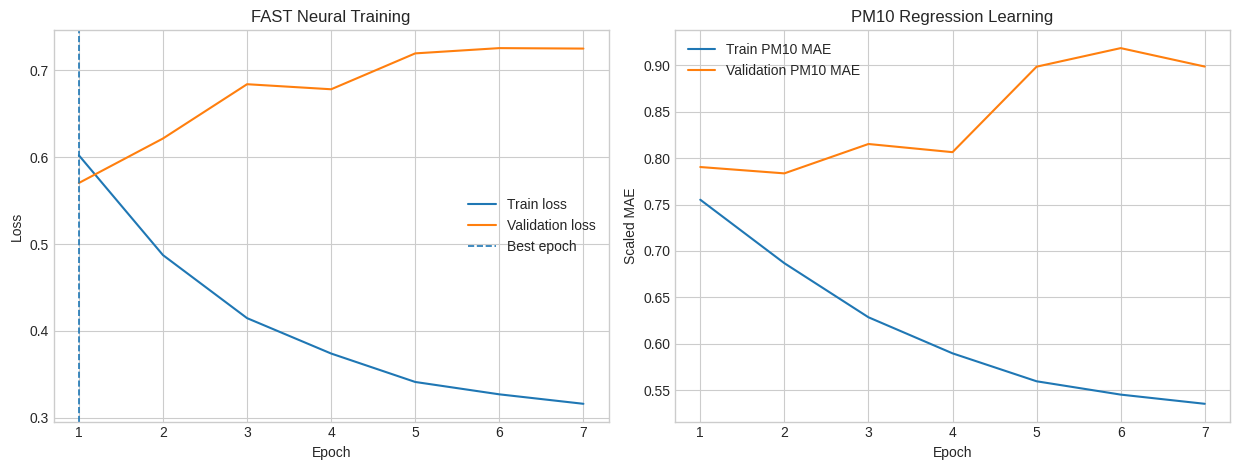

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

epochs = np.arange(1, len(history_df)+1)

axes[0].plot(epochs, history_df["loss"], label="Train loss")
axes[0].plot(epochs, history_df["val_loss"], label="Validation loss")
axes[0].axvline(
    best_epoch,
    linestyle="--",
    linewidth=1.2,
    label="Best epoch"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("FAST Neural Training")
axes[0].legend()

axes[1].plot(
    epochs,
    history_df["pm10_output_mae"],
    label="Train PM10 MAE"
)
axes[1].plot(
    epochs,
    history_df["val_pm10_output_mae"],
    label="Validation PM10 MAE"
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Scaled MAE")
axes[1].set_title("PM10 Regression Learning")
axes[1].legend()

plt.tight_layout()
save_figure("h24_training_history.png")


## 28. Actual vs Predicted

Saved: outputs_24h_gated_residual_final/results_figures/h24_actual_vs_predicted_grid.png


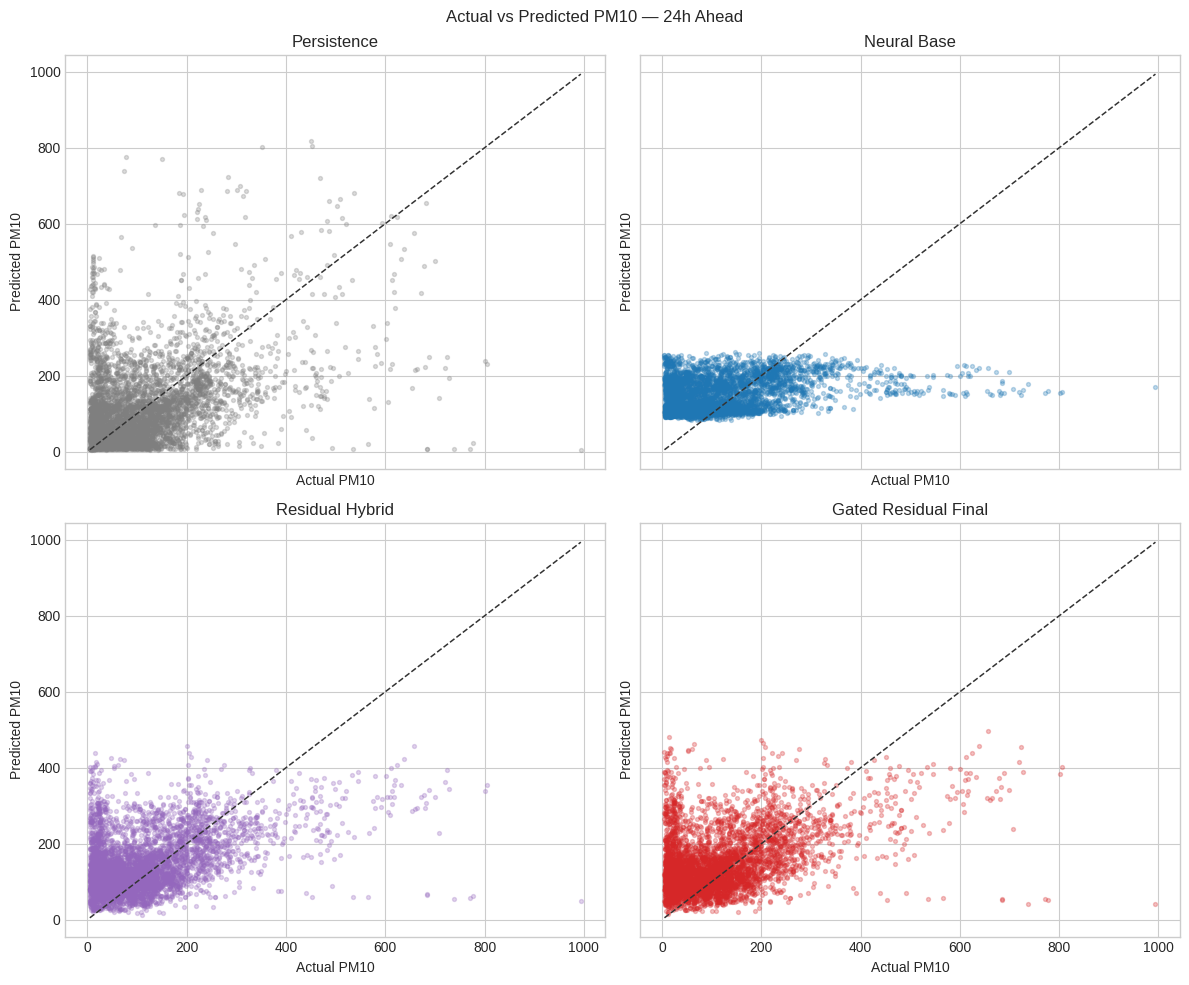

In [ ]:
max_points = 4500

if len(y_test) > max_points:
    idx = np.linspace(0, len(y_test)-1, max_points).astype(int)
else:
    idx = np.arange(len(y_test))

plot_models = [
    "Persistence",
    "Neural Base",
    "Residual Hybrid",
    "Gated Residual Final"
]

lo = float(
    min(
        y_test.min(),
        *[MODEL_PREDICTIONS[m].min() for m in plot_models]
    )
)

hi = float(
    max(
        y_test.max(),
        *[MODEL_PREDICTIONS[m].max() for m in plot_models]
    )
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10),
    sharex=True,
    sharey=True
)

axes = axes.ravel()

for ax, model_name in zip(axes, plot_models):
    pred = MODEL_PREDICTIONS[model_name]

    ax.scatter(
        y_test[idx],
        pred[idx],
        s=8,
        alpha=0.28,
        color=MODEL_COLORS[model_name]
    )

    ax.plot(
        [lo, hi],
        [lo, hi],
        "--",
        linewidth=1.1,
        color="#333333"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual PM10")
    ax.set_ylabel("Predicted PM10")

fig.suptitle("Actual vs Predicted PM10 — 24h Ahead")
plt.tight_layout()

save_figure("h24_actual_vs_predicted_grid.png")


## 29. Peak-centered overlay

Saved: outputs_24h_gated_residual_final/results_figures/h24_peak_centered_overlay.png


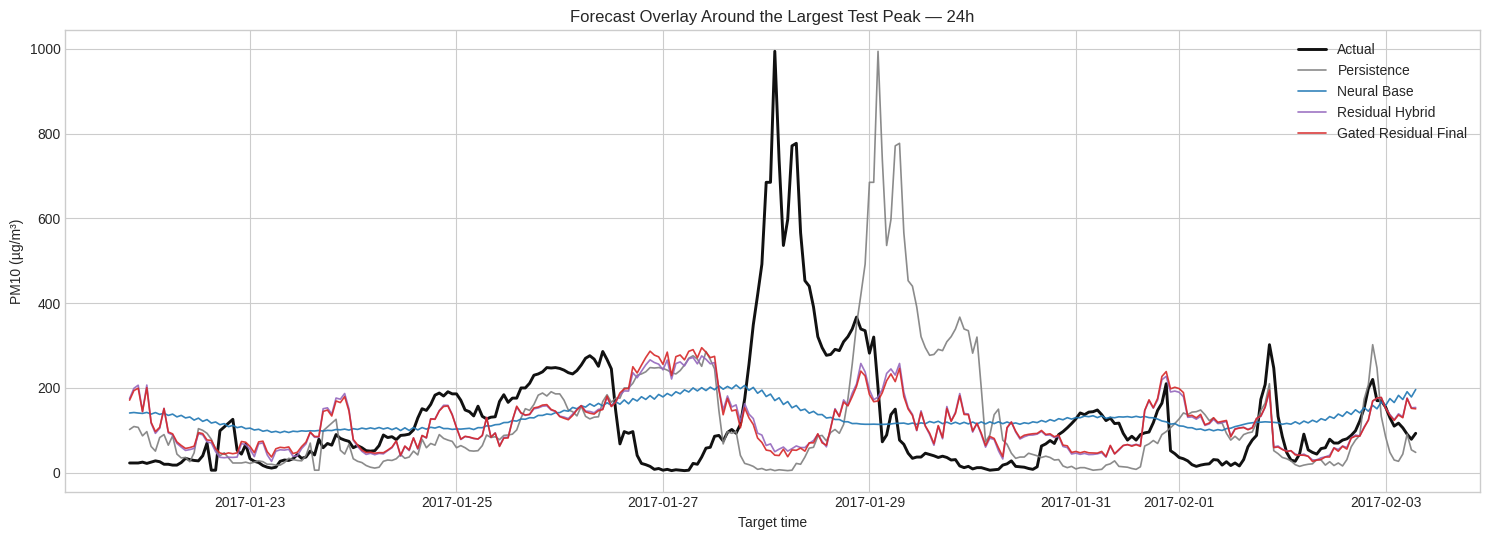

In [ ]:
WINDOW = 300
center_idx = int(np.argmax(y_test))

start = max(0, center_idx-WINDOW//2)
end = min(len(y_test), start+WINDOW)
start = max(0, end-WINDOW)

sl = slice(start, end)

plt.figure(figsize=(15, 5.5))

plt.plot(
    test["time"][sl],
    y_test[sl],
    linewidth=2.1,
    label="Actual",
    color=MODEL_COLORS["Actual"]
)

for model_name in plot_models:
    plt.plot(
        test["time"][sl],
        MODEL_PREDICTIONS[model_name][sl],
        linewidth=1.2,
        alpha=0.90,
        label=model_name,
        color=MODEL_COLORS[model_name]
    )

plt.xlabel("Target time")
plt.ylabel("PM10 (µg/m³)")
plt.title("Forecast Overlay Around the Largest Test Peak — 24h")
plt.legend()
plt.tight_layout()

save_figure("h24_peak_centered_overlay.png")


## 30. Overall vs Peak RMSE

Saved: outputs_24h_gated_residual_final/results_figures/overall_vs_peak_rmse_bar.png


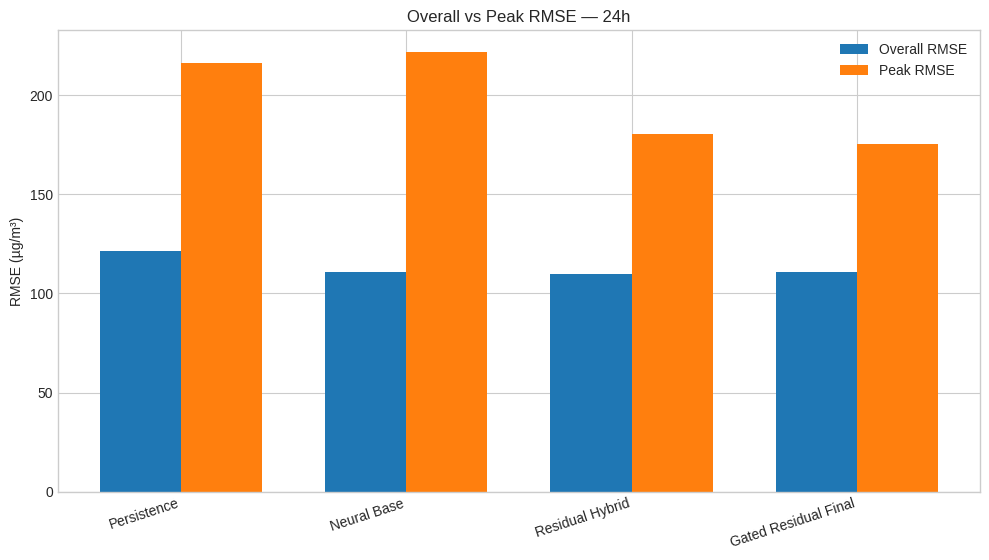

In [ ]:
bar_df = (
    test_metrics[["Model","RMSE"]]
    .rename(columns={"RMSE":"Overall_RMSE"})
    .merge(
        peak_test_metrics[["Model","RMSE"]]
        .rename(columns={"RMSE":"Peak_RMSE"}),
        on="Model",
        how="inner"
    )
)

x = np.arange(len(bar_df))
width = 0.36

plt.figure(figsize=(10, 5.7))

plt.bar(
    x-width/2,
    bar_df["Overall_RMSE"],
    width,
    label="Overall RMSE"
)

plt.bar(
    x+width/2,
    bar_df["Peak_RMSE"],
    width,
    label="Peak RMSE"
)

plt.xticks(
    x,
    bar_df["Model"],
    rotation=18,
    ha="right"
)
plt.ylabel("RMSE (µg/m³)")
plt.title("Overall vs Peak RMSE — 24h")
plt.legend()
plt.tight_layout()

save_figure("overall_vs_peak_rmse_bar.png")


## 31. Gate behavior

Saved: outputs_24h_gated_residual_final/results_figures/h24_gate_response.png


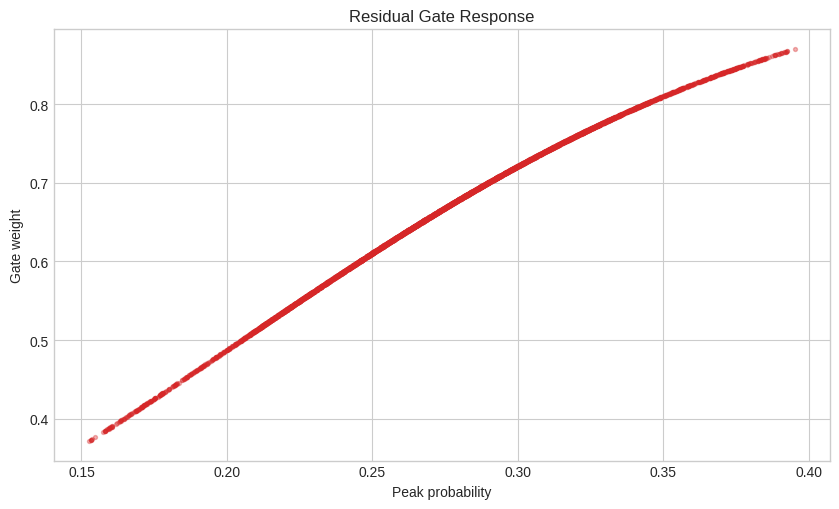

In [ ]:
plt.figure(figsize=(8.5, 5.2))

plt.scatter(
    test_peak_prob,
    test_gate,
    s=8,
    alpha=0.35,
    color=MODEL_COLORS["Gated Residual Final"]
)

plt.xlabel("Peak probability")
plt.ylabel("Gate weight")
plt.title("Residual Gate Response")
plt.tight_layout()

save_figure("h24_gate_response.png")


## 32. Peak magnitude comparison

Saved: outputs_24h_gated_residual_final/results_figures/h24_peak_actual_vs_predicted.png


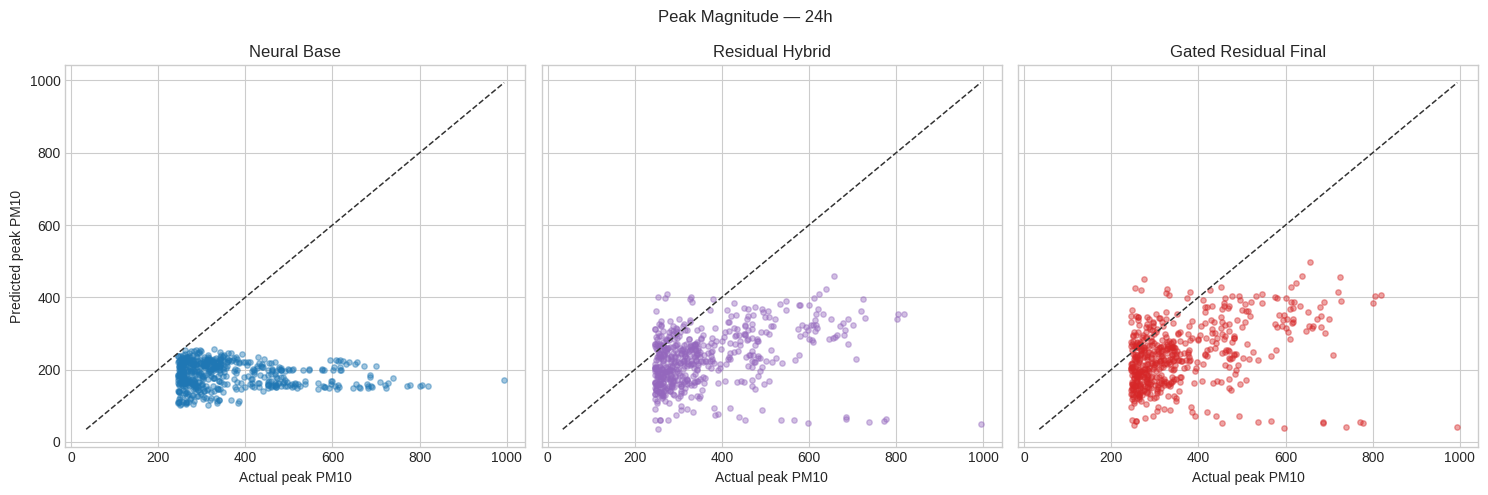

In [ ]:
peak_lo = float(
    min(
        peak_actual.min(),
        *[
            MODEL_PREDICTIONS[m][benchmark_peak_mask].min()
            for m in [
                "Neural Base",
                "Residual Hybrid",
                "Gated Residual Final"
            ]
        ]
    )
)

peak_hi = float(
    max(
        peak_actual.max(),
        *[
            MODEL_PREDICTIONS[m][benchmark_peak_mask].max()
            for m in [
                "Neural Base",
                "Residual Hybrid",
                "Gated Residual Final"
            ]
        ]
    )
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)

for ax, model_name in zip(
    axes,
    [
        "Neural Base",
        "Residual Hybrid",
        "Gated Residual Final"
    ]
):
    pred = MODEL_PREDICTIONS[model_name][benchmark_peak_mask]

    ax.scatter(
        peak_actual,
        pred,
        s=15,
        alpha=0.42,
        color=MODEL_COLORS[model_name]
    )

    ax.plot(
        [peak_lo, peak_hi],
        [peak_lo, peak_hi],
        "--",
        linewidth=1.1,
        color="#333333"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual peak PM10")

axes[0].set_ylabel("Predicted peak PM10")

fig.suptitle("Peak Magnitude — 24h")
plt.tight_layout()

save_figure("h24_peak_actual_vs_predicted.png")


## 33. Residual Corrector feature importance

Saved: outputs_24h_gated_residual_final/results_figures/h24_residual_feature_importance.png


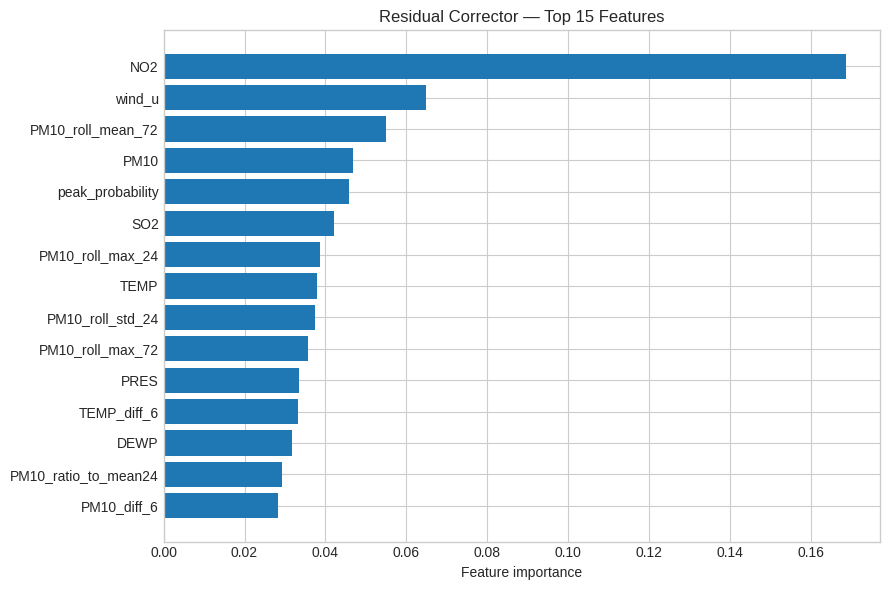

In [ ]:
importance = pd.Series(
    residual_model.feature_importances_,
    index=X_cal_corr.columns
).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))

plt.barh(
    importance.index[::-1],
    importance.values[::-1]
)

plt.xlabel("Feature importance")
plt.title("Residual Corrector — Top 15 Features")
plt.tight_layout()

save_figure("h24_residual_feature_importance.png")


## 34. ذخیره خروجی‌ها

In [ ]:
test_metrics.to_csv(
    OUTPUT_DIR / "test_metrics.csv",
    index=False
)

peak_metrics_operational.to_csv(
    OUTPUT_DIR / "peak_test_metrics_operational_trainP90.csv",
    index=False
)

peak_test_metrics.to_csv(
    OUTPUT_DIR / "peak_test_metrics.csv",
    index=False
)

peak_classification_metrics.to_csv(
    OUTPUT_DIR / "peak_classification_metrics.csv",
    index=False
)

peak_magnitude_diagnostics.to_csv(
    OUTPUT_DIR / "peak_magnitude_diagnostics.csv",
    index=False
)

headline_improvements.to_csv(
    OUTPUT_DIR / "headline_improvements.csv",
    index=False
)

joblib.dump(
    feature_scaler,
    OUTPUT_DIR / "feature_scaler.joblib"
)

joblib.dump(
    target_scaler,
    OUTPUT_DIR / "target_scaler.joblib"
)

joblib.dump(
    residual_model,
    OUTPUT_DIR / "xgboost_residual_corrector.joblib"
)

neural_model.save(
    OUTPUT_DIR / "fast_peak_aware_cnn_gru_24h.keras"
)

config = {
    "model_name": "24H Peak-Aware Gated Residual CNN-GRU FINAL",
    "horizon_hours": HORIZON_HOURS,
    "lookback_hours": LOOKBACK_HOURS,
    "train_peak_threshold_PM10": TRAIN_PEAK_THRESHOLD,
    "best_nn_epoch": best_epoch,
    "nn_training_seconds": nn_training_seconds,
    "xgb_training_seconds": xgb_training_seconds,
    "total_training_seconds": nn_training_seconds + xgb_training_seconds,
    "calibration_F2_threshold": CAL_F2_THRESHOLD,
    "gate_center": GATE_CENTER,
    "gate_temperature": GATE_TEMPERATURE,
    "correction_scale": CORRECTION_SCALE,
    "features": FEATURES,
    "architecture": {
        "stage_1": (
            "Multi-scale causal CNN -> stride-2 temporal downsampling "
            "-> GRU(64) -> linear temporal attention -> PM10 + Peak heads"
        ),
        "stage_2": (
            "XGBoost residual correction on separate chronological calibration data"
        ),
        "final_fusion": (
            "Final PM10 = Neural Base + "
            "scale * sigmoid((PeakProb-center)/temperature) * Residual"
        )
    },
    "methodological_note": (
        "All preprocessing statistics and Train-P90 are estimated only from "
        "the NN training partition. NN validation is used for early stopping. "
        "Residual model, peak threshold calibration, and gate parameters are "
        "selected only on the later chronological calibration partition. "
        "The test partition is untouched until final evaluation."
    )
}

with open(
    OUTPUT_DIR / "experiment_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        config,
        f,
        ensure_ascii=False,
        indent=2
    )

print("Saved to:", OUTPUT_DIR.resolve())


Saved to: /content/outputs_24h_gated_residual_final


## 35. ZIP خروجی

In [ ]:
zip_path = shutil.make_archive(
    str(OUTPUT_DIR),
    "zip",
    root_dir=OUTPUT_DIR
)

print("ZIP created:", zip_path)

# Colab download:
# from google.colab import files
# files.download(zip_path)


ZIP created: /content/outputs_24h_gated_residual_final.zip


## خروجی‌های کلیدی

برای تصمیم نهایی درباره موفقیت مدل:

- `test_metrics.csv`
- `peak_test_metrics.csv`
- `peak_magnitude_diagnostics.csv`
- `peak_classification_metrics.csv`
- `headline_improvements.csv`
- `calibration_gate_search.csv`
- `test_predictions.csv`

معیار اصلی:
- Overall RMSE نباید نسبت به Residual Hybrid خراب شود.
- Peak RMSE/MAE باید حفظ یا بهتر شود.
- Peak underprediction rate بهتر است کاهش یابد.
- زمان اجرا باید نزدیک نسخه FAST باقی بماند.


# 36. Additional thesis visualizations — no model changes

این بخش **صرفاً مصورسازی تکمیلی نتایج** است و هیچ تغییری در معماری، preprocessing، feature engineering، loss، optimizer، calibration، XGBoost residual corrector، gate، thresholdها یا predictionهای مدل ایجاد نمی‌کند.

تمام نمودارها مستقیماً از متغیرها و DataFrameهای محاسبه‌شده در سلول‌های اصلی نوت‌بوک استفاده می‌کنند. هر شکل:

- داخل خود Notebook با `plt.show()` نمایش داده می‌شود؛
- با `dpi=300` در `results_figures/` ذخیره می‌شود؛
- از رنگ ثابت هر مدل در `MODEL_COLORS` استفاده می‌کند.


In [ ]:
# Visualization-only imports / style. No modeling code is changed.
try:
    import seaborn as sns
except Exception:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "seaborn"])
    import seaborn as sns

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except Exception:
    pass
sns.set_theme(style="whitegrid")

EXTRA_FIGURES = []

def save_and_show_extra(filename):
    path = FIG_DIR / filename
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)
    EXTRA_FIGURES.append(str(path))
    plt.show()
    plt.close()


## 36.1 Overall metrics comparison grid

Saved: outputs_24h_gated_residual_final/results_figures/h24_all_metrics_comparison_grid.png


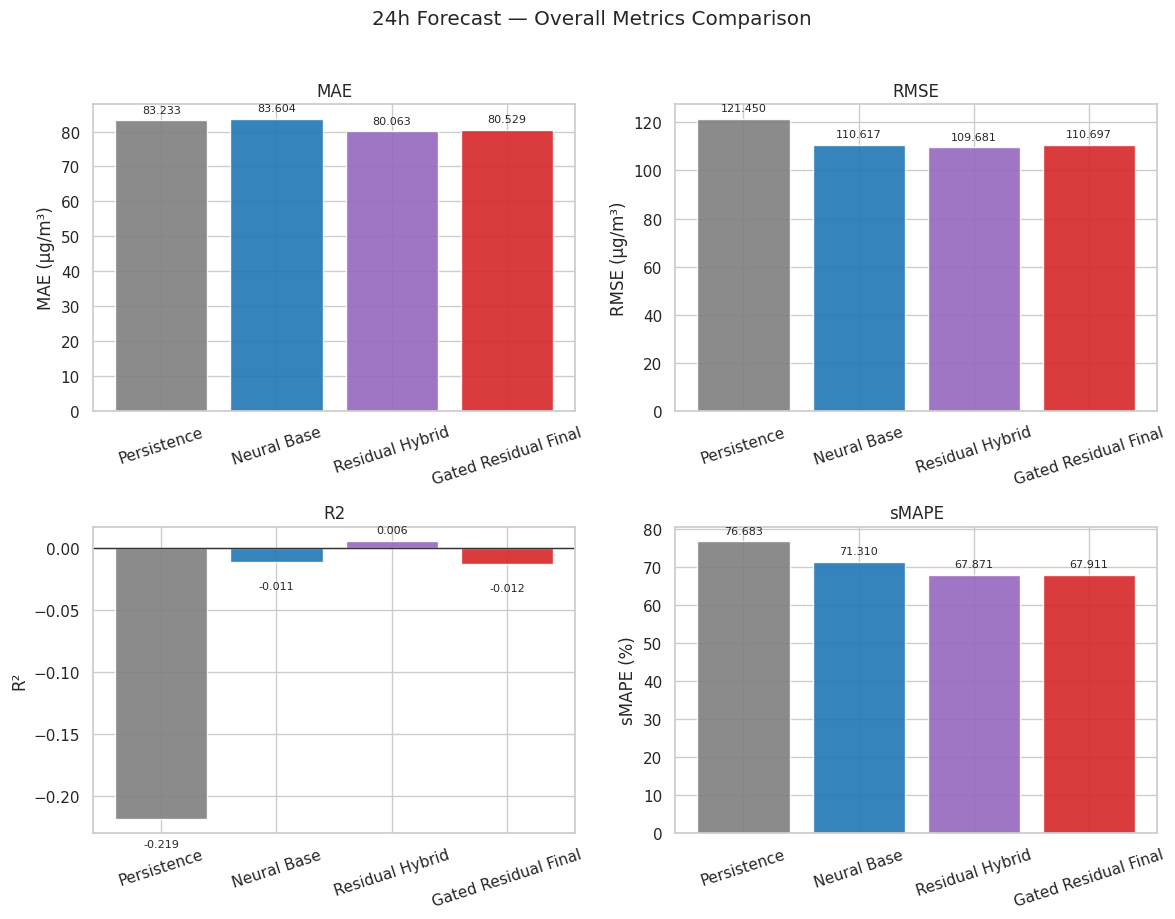

In [ ]:
metric_specs = [
    ("MAE", "MAE (µg/m³)", False),
    ("RMSE", "RMSE (µg/m³)", False),
    ("R2", "R²", True),
    ("sMAPE_percent", "sMAPE (%)", False),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()

ordered_models = [
    "Persistence",
    "Neural Base",
    "Residual Hybrid",
    "Gated Residual Final",
]

plot_df = test_metrics.set_index("Model").loc[ordered_models].reset_index()

for ax, (metric, ylabel, higher_better) in zip(axes, metric_specs):
    colors = [MODEL_COLORS[m] for m in plot_df["Model"]]
    bars = ax.bar(plot_df["Model"], plot_df[metric], color=colors, alpha=0.9)
    ax.set_title(metric if metric != "sMAPE_percent" else "sMAPE")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=18)
    if metric == "R2":
        ax.axhline(0, color="#333333", linewidth=1.0)
    for bar, val in zip(bars, plot_df[metric]):
        ax.annotate(
            f"{val:.3f}",
            (bar.get_x() + bar.get_width()/2, bar.get_height()),
            xytext=(0, 4 if val >= 0 else -14),
            textcoords="offset points",
            ha="center",
            va="bottom" if val >= 0 else "top",
            fontsize=8
        )

fig.suptitle("24h Forecast — Overall Metrics Comparison", y=1.02)
plt.tight_layout()
save_and_show_extra("h24_all_metrics_comparison_grid.png")


## 36.2 Improvement over Persistence — overall vs peak

Saved: outputs_24h_gated_residual_final/results_figures/h24_improvement_over_persistence_bar.png


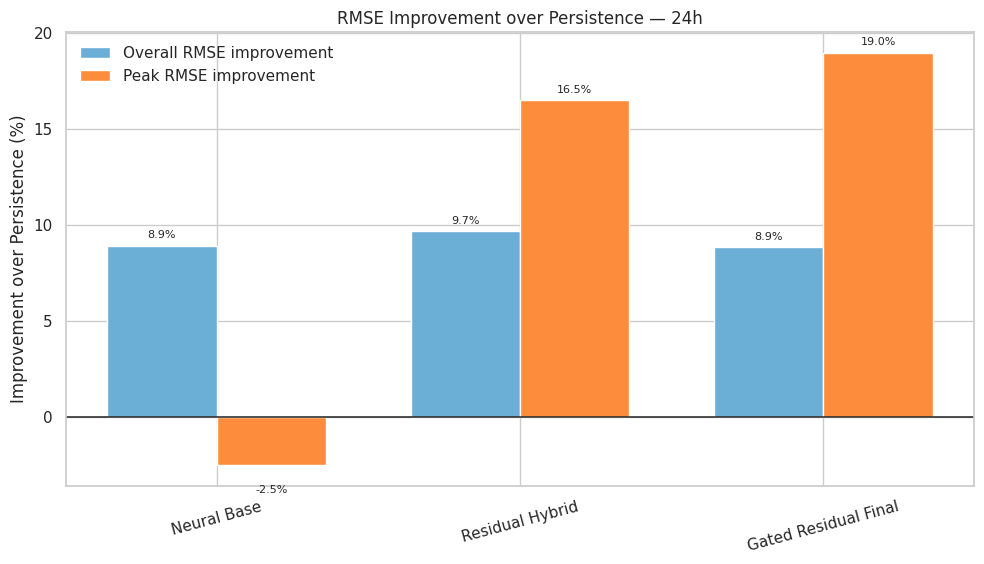

In [ ]:
baseline_overall_rmse = float(overall_lookup.loc["Persistence", "RMSE"])
baseline_peak_rmse = float(peak_lookup.loc["Persistence", "RMSE"])

learned_models = ["Neural Base", "Residual Hybrid", "Gated Residual Final"]
imp_rows = []
for m in learned_models:
    imp_rows.append({
        "Model": m,
        "Overall_RMSE_improvement_pct": 100.0 * (
            baseline_overall_rmse - float(overall_lookup.loc[m, "RMSE"])
        ) / baseline_overall_rmse,
        "Peak_RMSE_improvement_pct": 100.0 * (
            baseline_peak_rmse - float(peak_lookup.loc[m, "RMSE"])
        ) / baseline_peak_rmse,
    })

imp_df = pd.DataFrame(imp_rows)

x = np.arange(len(imp_df))
width = 0.36
plt.figure(figsize=(10, 5.8))

b1 = plt.bar(
    x - width/2,
    imp_df["Overall_RMSE_improvement_pct"],
    width,
    label="Overall RMSE improvement",
    color="#6baed6"
)
b2 = plt.bar(
    x + width/2,
    imp_df["Peak_RMSE_improvement_pct"],
    width,
    label="Peak RMSE improvement",
    color="#fd8d3c"
)

plt.axhline(0, color="#222222", linewidth=1.1)
plt.xticks(x, imp_df["Model"], rotation=15)
plt.ylabel("Improvement over Persistence (%)")
plt.title("RMSE Improvement over Persistence — 24h")
plt.legend()

for bars in [b1, b2]:
    for bar in bars:
        h = bar.get_height()
        plt.annotate(
            f"{h:.1f}%",
            (bar.get_x()+bar.get_width()/2, h),
            xytext=(0, 4 if h >= 0 else -14),
            textcoords="offset points",
            ha="center",
            va="bottom" if h >= 0 else "top",
            fontsize=8
        )

plt.tight_layout()
save_and_show_extra("h24_improvement_over_persistence_bar.png")


## 36.3 Residual diagnostics

Saved: outputs_24h_gated_residual_final/results_figures/h24_residuals_grid.png


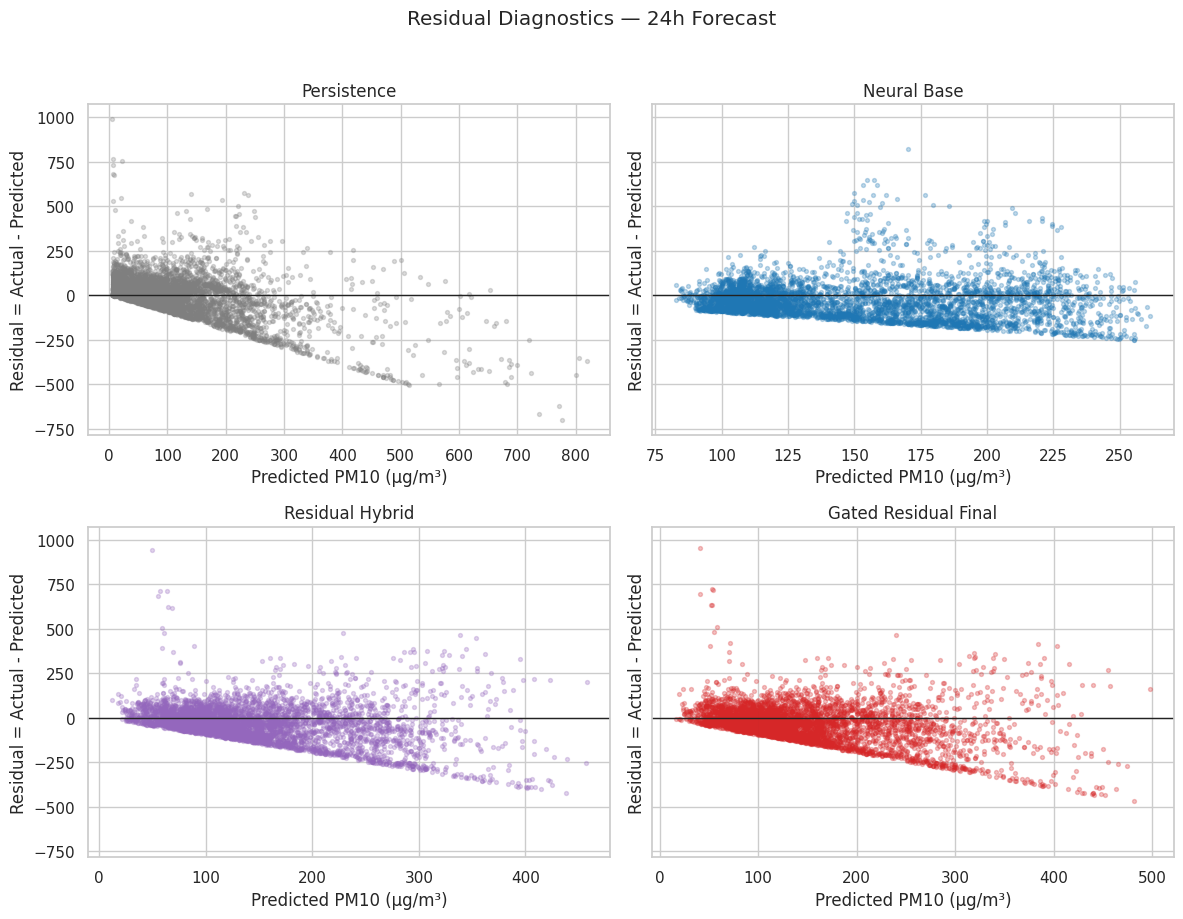

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
axes = axes.ravel()

for ax, model_name in zip(axes, ordered_models):
    pred = MODEL_PREDICTIONS[model_name]
    residual = y_test - pred

    idx = np.arange(len(y_test))
    if len(idx) > 4500:
        idx = np.linspace(0, len(idx)-1, 4500).astype(int)

    ax.scatter(
        pred[idx],
        residual[idx],
        s=8,
        alpha=0.28,
        color=MODEL_COLORS[model_name]
    )
    ax.axhline(0, color="#222222", linewidth=1.0)
    ax.set_title(model_name)
    ax.set_xlabel("Predicted PM10 (µg/m³)")
    ax.set_ylabel("Residual = Actual - Predicted")

fig.suptitle("Residual Diagnostics — 24h Forecast", y=1.02)
plt.tight_layout()
save_and_show_extra("h24_residuals_grid.png")


## 36.4 PM10 distribution and peak thresholds

Saved: outputs_24h_gated_residual_final/results_figures/pm10_distribution_with_peak_threshold.png


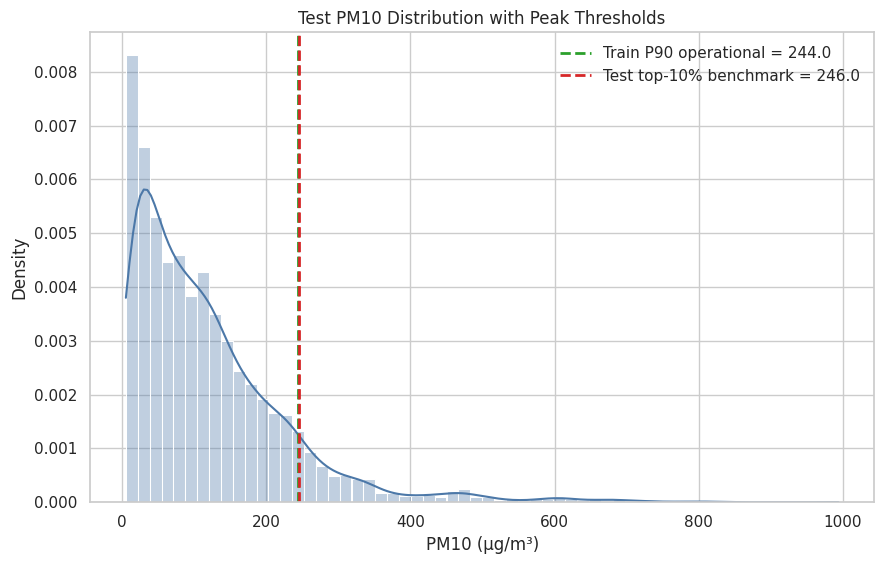

In [ ]:
plt.figure(figsize=(9, 5.8))
sns.histplot(
    y_test,
    bins=60,
    stat="density",
    kde=True,
    color="#4c78a8",
    alpha=0.35
)

plt.axvline(
    TRAIN_PEAK_THRESHOLD,
    color="#2ca02c",
    linestyle="--",
    linewidth=2,
    label=f"Train P90 operational = {TRAIN_PEAK_THRESHOLD:.1f}"
)
plt.axvline(
    test_top10_threshold,
    color="#d62728",
    linestyle="--",
    linewidth=2,
    label=f"Test top-10% benchmark = {test_top10_threshold:.1f}"
)

plt.xlabel("PM10 (µg/m³)")
plt.ylabel("Density")
plt.title("Test PM10 Distribution with Peak Thresholds")
plt.legend()
plt.tight_layout()
save_and_show_extra("pm10_distribution_with_peak_threshold.png")


## 36.5 Rank heatmap — overall and peak metrics

Saved: outputs_24h_gated_residual_final/results_figures/h24_rank_heatmap.png


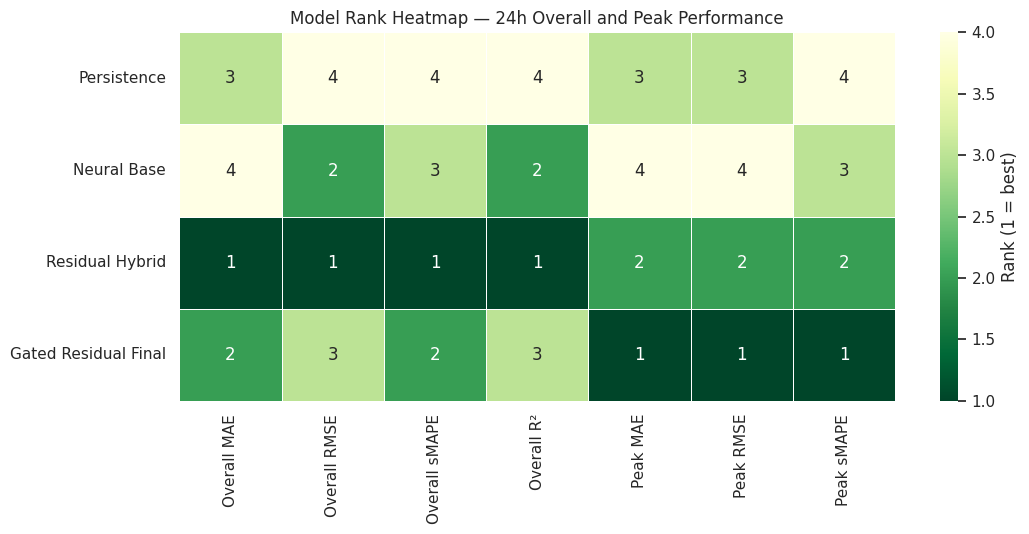

In [ ]:
overall_rank = test_metrics.set_index("Model")[["MAE", "RMSE", "sMAPE_percent"]].rank(method="min", ascending=True)
overall_r2_rank = test_metrics.set_index("Model")[["R2"]].rank(method="min", ascending=False)
peak_rank = peak_test_metrics.set_index("Model")[["MAE", "RMSE", "sMAPE_percent"]].rank(method="min", ascending=True)

rank_df = pd.concat([
    overall_rank.rename(columns={
        "MAE":"Overall MAE",
        "RMSE":"Overall RMSE",
        "sMAPE_percent":"Overall sMAPE"
    }),
    overall_r2_rank.rename(columns={"R2":"Overall R²"}),
    peak_rank.rename(columns={
        "MAE":"Peak MAE",
        "RMSE":"Peak RMSE",
        "sMAPE_percent":"Peak sMAPE"
    })
], axis=1).loc[ordered_models]

plt.figure(figsize=(11, 5.5))
sns.heatmap(
    rank_df,
    annot=True,
    fmt=".0f",
    cmap="YlGn_r",
    cbar_kws={"label":"Rank (1 = best)"},
    linewidths=0.5
)
plt.title("Model Rank Heatmap — 24h Overall and Peak Performance")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
save_and_show_extra("h24_rank_heatmap.png")


## 36.6 Efficiency scatter — training time vs RMSE

Saved: outputs_24h_gated_residual_final/results_figures/h24_efficiency_scatter.png


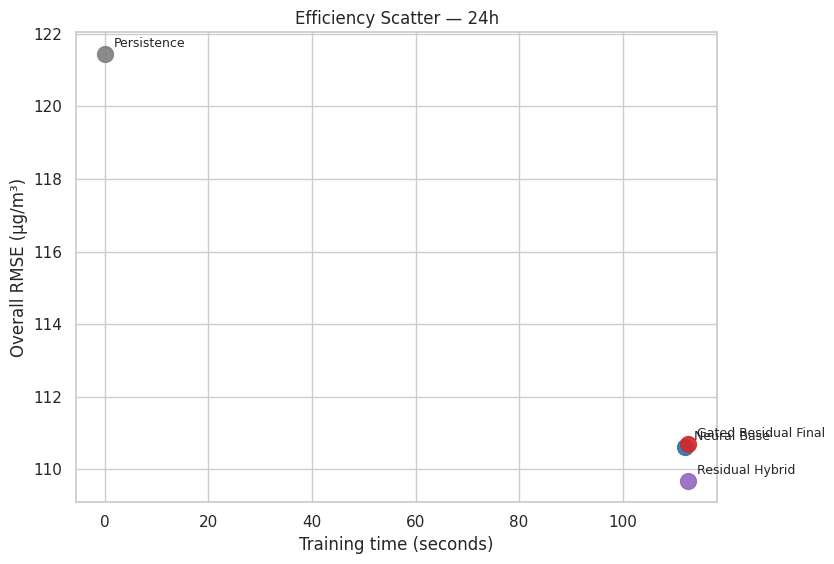

In [ ]:
plt.figure(figsize=(8.5, 5.8))

for _, row in test_metrics.iterrows():
    model_name = row["Model"]
    plt.scatter(
        row["Training_seconds"],
        row["RMSE"],
        s=130,
        color=MODEL_COLORS[model_name],
        alpha=0.9
    )
    plt.annotate(
        model_name,
        (row["Training_seconds"], row["RMSE"]),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Training time (seconds)")
plt.ylabel("Overall RMSE (µg/m³)")
plt.title("Efficiency Scatter — 24h")
plt.tight_layout()
save_and_show_extra("h24_efficiency_scatter.png")


## 36.7 Peak classification confusion matrix

Saved: outputs_24h_gated_residual_final/results_figures/h24_peak_confusion_matrix.png


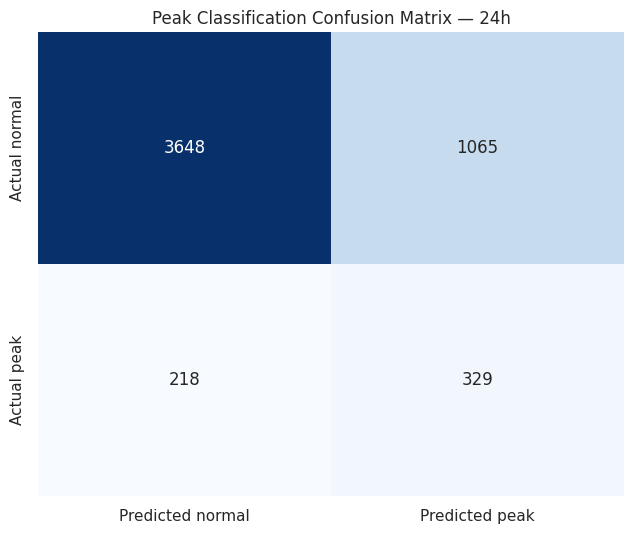

In [ ]:
cm = confusion_matrix(y_peak_true, y_peak_hat)

plt.figure(figsize=(6.5, 5.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted normal", "Predicted peak"],
    yticklabels=["Actual normal", "Actual peak"]
)
plt.title("Peak Classification Confusion Matrix — 24h")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
save_and_show_extra("h24_peak_confusion_matrix.png")


## 36.8 Gate activation for normal vs peak samples

Saved: outputs_24h_gated_residual_final/results_figures/h24_gate_distribution_peak_vs_normal.png


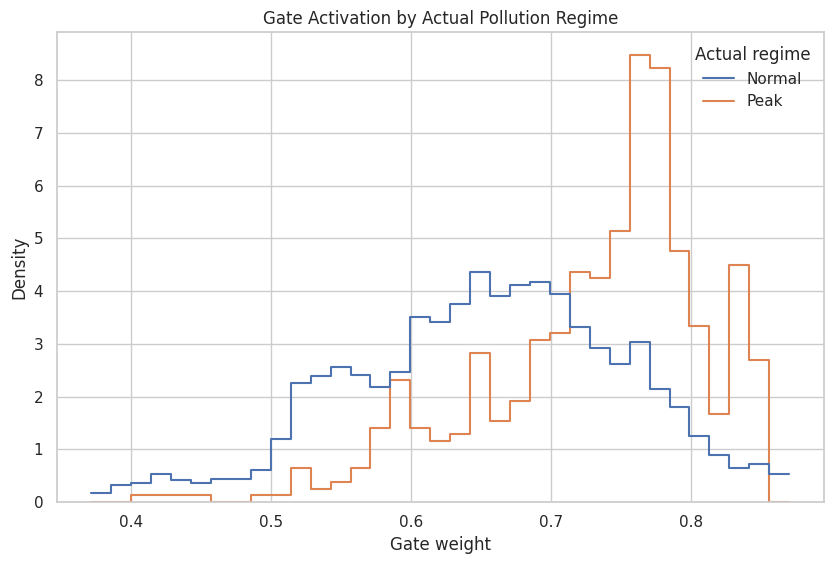

In [ ]:
gate_plot_df = pd.DataFrame({
    "Gate weight": test_gate,
    "Actual regime": np.where(y_peak_true == 1, "Peak", "Normal")
})

plt.figure(figsize=(8.5, 5.8))
sns.histplot(
    data=gate_plot_df,
    x="Gate weight",
    hue="Actual regime",
    bins=35,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)
plt.xlabel("Gate weight")
plt.ylabel("Density")
plt.title("Gate Activation by Actual Pollution Regime")
plt.tight_layout()
save_and_show_extra("h24_gate_distribution_peak_vs_normal.png")


## 36.9 Peak magnitude capture ratios

Saved: outputs_24h_gated_residual_final/results_figures/h24_peak_capture_ratio_bar.png


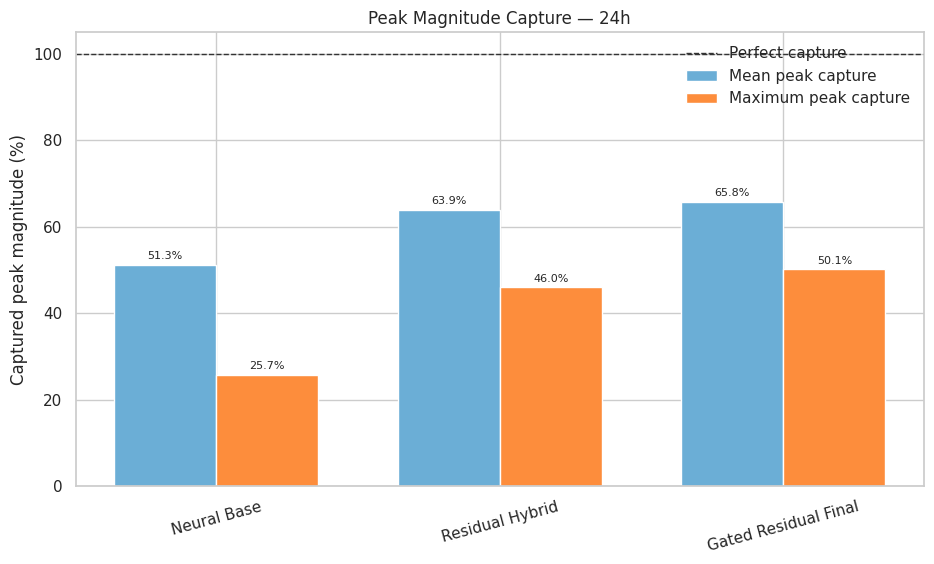

In [ ]:
capture_df = peak_magnitude_diagnostics.copy()

x = np.arange(len(capture_df))
width = 0.36
plt.figure(figsize=(9.5, 5.8))

bars1 = plt.bar(
    x-width/2,
    100*capture_df["Mean_peak_capture_ratio"],
    width,
    label="Mean peak capture",
    color="#6baed6"
)
bars2 = plt.bar(
    x+width/2,
    100*capture_df["Max_peak_capture_ratio"],
    width,
    label="Maximum peak capture",
    color="#fd8d3c"
)

plt.xticks(x, capture_df["Model"], rotation=15)
plt.ylabel("Captured peak magnitude (%)")
plt.title("Peak Magnitude Capture — 24h")
plt.axhline(100, color="#333333", linestyle="--", linewidth=1.0, label="Perfect capture")
plt.legend()

for bars in [bars1, bars2]:
    for b in bars:
        v = b.get_height()
        plt.annotate(
            f"{v:.1f}%",
            (b.get_x()+b.get_width()/2, v),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

plt.tight_layout()
save_and_show_extra("h24_peak_capture_ratio_bar.png")


## 36.10 Error progression across PM10 deciles

Saved: outputs_24h_gated_residual_final/results_figures/h24_mae_by_pm10_decile.png


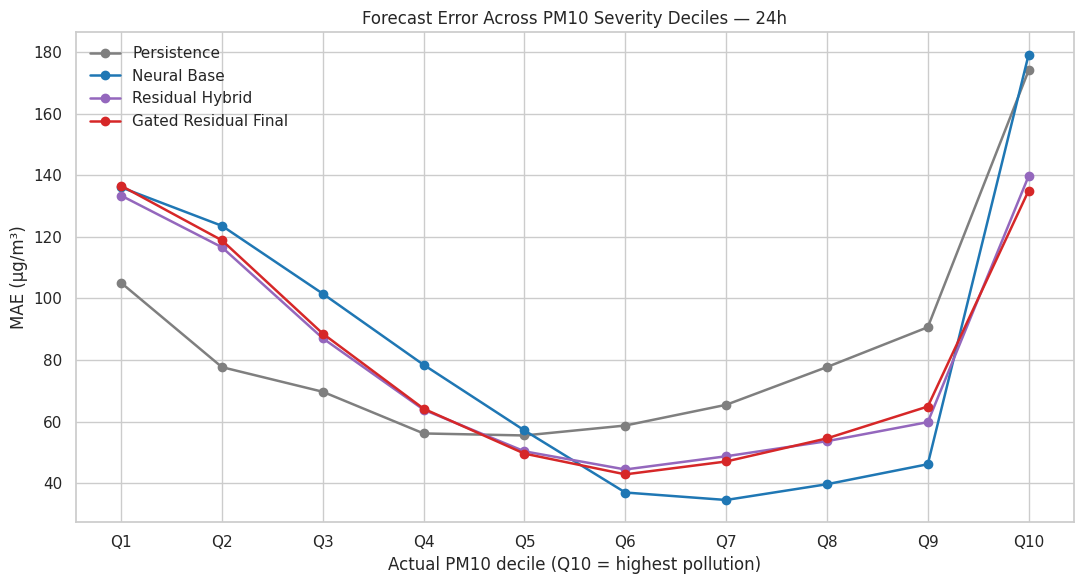

In [ ]:
# Quantile-wise MAE reveals where each model loses accuracy as pollution severity rises.
quantile_labels = [f"Q{i}" for i in range(1, 11)]
quantile_bins = pd.qcut(
    pd.Series(y_test),
    q=10,
    labels=quantile_labels,
    duplicates="drop"
)

quantile_rows = []
for q in pd.Series(quantile_bins).dropna().unique():
    mask = (quantile_bins == q).to_numpy()
    for model_name in ordered_models:
        quantile_rows.append({
            "PM10_decile": str(q),
            "Model": model_name,
            "MAE": mean_absolute_error(y_test[mask], MODEL_PREDICTIONS[model_name][mask])
        })

quantile_error_df = pd.DataFrame(quantile_rows)
quantile_error_df["order"] = quantile_error_df["PM10_decile"].str.extract(r"(\d+)").astype(int)
quantile_error_df = quantile_error_df.sort_values(["order", "Model"])

plt.figure(figsize=(11, 6))
for model_name in ordered_models:
    d = quantile_error_df[quantile_error_df["Model"] == model_name].sort_values("order")
    plt.plot(
        d["PM10_decile"],
        d["MAE"],
        marker="o",
        linewidth=1.8,
        label=model_name,
        color=MODEL_COLORS[model_name]
    )

plt.xlabel("Actual PM10 decile (Q10 = highest pollution)")
plt.ylabel("MAE (µg/m³)")
plt.title("Forecast Error Across PM10 Severity Deciles — 24h")
plt.legend()
plt.tight_layout()
save_and_show_extra("h24_mae_by_pm10_decile.png")


## 36.11 Calibration gate-search visualization

Saved: outputs_24h_gated_residual_final/results_figures/h24_calibration_gate_search_heatmap.png


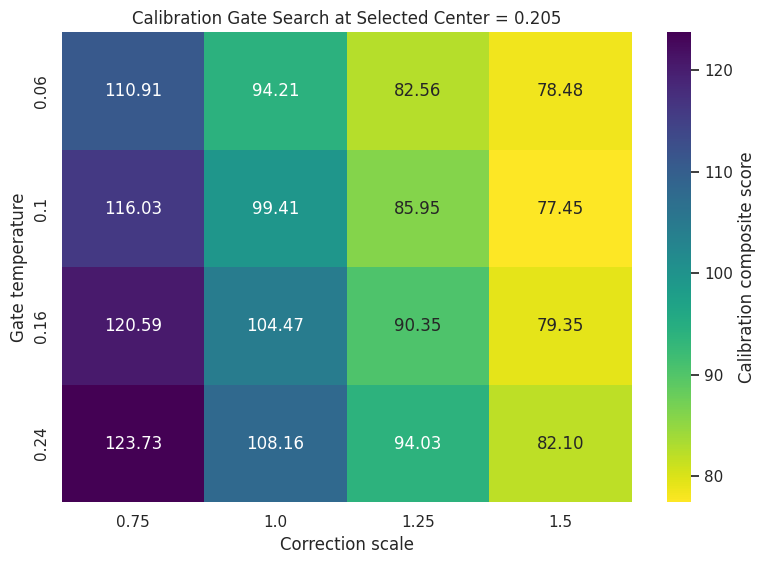

In [ ]:
# Visualizes the calibration-only search that selected the final gate.
# Test data are not used in this figure or in the underlying gate search.
selected_center_df = gate_search[np.isclose(gate_search["center"], GATE_CENTER)].copy()
heat = selected_center_df.pivot_table(
    index="temperature",
    columns="correction_scale",
    values="composite_score",
    aggfunc="min"
).sort_index()

plt.figure(figsize=(8, 5.8))
sns.heatmap(
    heat,
    annot=True,
    fmt=".2f",
    cmap="viridis_r",
    cbar_kws={"label":"Calibration composite score"}
)
plt.title(f"Calibration Gate Search at Selected Center = {GATE_CENTER:.3f}")
plt.xlabel("Correction scale")
plt.ylabel("Gate temperature")
plt.tight_layout()
save_and_show_extra("h24_calibration_gate_search_heatmap.png")


## 36.12 Extra-figure manifest

In [1]:
extra_figure_manifest = pd.DataFrame({"figure_path": EXTRA_FIGURES})
display(extra_figure_manifest)
extra_figure_manifest.to_csv(
    OUTPUT_DIR / "extra_figure_manifest.csv",
    index=False
)
print(f"Generated {len(EXTRA_FIGURES)} additional thesis figures.")


NameError: name 'pd' is not defined

# ذخیره و دریافت همه نمودارها

این بخش فقط برای **جمع‌آوری و دریافت خروجی شکل‌ها** اضافه شده است و هیچ تغییری در مدل، داده‌ها، آموزش، ارزیابی یا کدهای مصورسازی قبلی ایجاد نمی‌کند.

تمام نمودارهایی که در طول Notebook با `save_figure(...)` یا `save_and_show_extra(...)` ذخیره شده‌اند، از پوشه `results_figures` جمع‌آوری می‌شوند و علاوه بر فایل‌های PNG مجزا، در یک فایل ZIP نیز قرار می‌گیرند تا بتوان آن‌ها را یک‌جا دریافت کرد.

In [ ]:
# ============================================================
# EXPORT ALL SAVED FIGURES
# Added only for convenient access/download.
# No modeling or visualization code above is modified.
# ============================================================

from pathlib import Path
import shutil
import os

# FIG_DIR is already defined earlier in the original notebook:
# outputs_24h_gated_residual_final/results_figures

FIG_DIR.mkdir(parents=True, exist_ok=True)

saved_figures = sorted(
    list(FIG_DIR.glob("*.png")) +
    list(FIG_DIR.glob("*.jpg")) +
    list(FIG_DIR.glob("*.jpeg")) +
    list(FIG_DIR.glob("*.pdf"))
)

print(f"Number of saved figures: {len(saved_figures)}")
print(f"Figure directory: {FIG_DIR.resolve()}\n")

for i, fig_path in enumerate(saved_figures, start=1):
    size_mb = fig_path.stat().st_size / (1024**2)
    print(f"{i:02d}. {fig_path.name}  ({size_mb:.2f} MB)")

# Create one ZIP archive containing all figures.
zip_base = OUTPUT_DIR / "Peak_Aware_24H_All_Figures"
zip_path = Path(
    shutil.make_archive(
        str(zip_base),
        "zip",
        root_dir=str(FIG_DIR)
    )
)

print("\nZIP archive created:")
print(zip_path.resolve())

# If running in Google Colab, automatically offer the ZIP for download.
try:
    from google.colab import files
    print("\nGoogle Colab detected — starting ZIP download...")
    files.download(str(zip_path))
except Exception:
    print(
        "\nAutomatic download is only available in Google Colab. "
        "The ZIP file is already saved at the path shown above."
    )
